# Phase-1 Plan

**Goal:** study the data pattern / distribution of the gene-KO growth-rate time series (462 different single-cell KO with 2 seeds simulation) and compare 4 media: basal, acetate, succinate, amino acids (aa).\
The basal media simulation is set to a maximum of 12 generations; acetate, succinate, and aa are set to a maximum of 20 generations. These limits were chosen based on a previous generation-level deviation analysis.\
Some simulation are ended before pre-set maximum simulation and the resulting maximum simulation can be found in the summary file:
`/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_acetate_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_basal_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_succinate_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_with_aa_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_wildtype_with_aa_seed1_2_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_wildtype_3media_seed100_101_all.csv
`. \
Proposed window based on generation-difference for each media:
`/user/home/il22158/work/vEcoli/job/tdi_summary_40trial_5media_composite_tdi.csv`

**Data:** 
`/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_acetate_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_basal_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_succinate_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_with_aa_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_wildtype_3media_seed100_101_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_wildtype_with_aa_seed1_2_all.parquet
`, one file per medium, concatenated with a `medium` column.

Wildtype (`baseline`) is included in each medium's pool and summaries. Black dots highlight wildtype in scatter plots; the red histogram line is the equally weighted mean of the valid wildtype seed means, before plot trimming. For the seed-agreement plots only, aa wildtype seeds 1 and 2 occupy the seed 100 and 101 axes respectively; exported seed IDs remain unchanged.

**Preliminary checks**
1. Inspect shape, dtypes, NaN/inf and time range per medium. *Reason:* files come from separate simulation runs; differing lengths or missing values would bias every comparison.
2. Choose the unit of analysis: the 2 seeds of one knockout are replicates, so aggregate to one value per (medium, gene KO) before testing. *Reason:* pooling all rows treats correlated observations as independent and makes p-values far too small.

**Step 1. Per-KO summary and variability**

Preprocessing
- Restrict the time-series rows with proposed windows for each media (/user/home/il22158/work/vEcoli/job/tdi_summary_40trial_5media_composite_tdi.csv). A run is valid if it has more than one distinct nonzero output time point; separately record whether it reached the target generation.
- Return run-validity and division-outcome counts, plus the maximum generation reached for each medium/KO/seed. Do not label a run that misses the target generation as a failed simulation; it is a valid run with division target not reached.
- Coversion: from 1/s to 1/h.
- For valid runs that do not reach the window end, use available observations within the window; do not impute zero. Runs without window observations have no window mean. Invalid runs (one or zero distinct nonzero output time points) are excluded from KO means.

Plotting
- For the per-KO distribution, average the available seed means within each KO and medium. A KO is "common" when it has a non-missing per-KO mean in all four media; this does not require both seeds or completion to the maximum generation. The plotted distributions and summary table use the same common-KO set (n=? in the current output).
- The seed-to-seed scatter uses a separate inclusion rule: a KO is plotted for a medium when one seed means are present, each calculated from that seed's available time points within generations window. It does not require either seed to reach the maximum generation. The legend's n is this per-medium count of KOs with both seed means (? aa, ? acetate, ? basal, and ? succinate in the current output); it is not the common-KO count.
- Show the per-KO distribution with a box plot and overlaid points, plus the seed-1 versus seed-2 scatter plot with a 1:1 reference line. Report the common-KO count, median, and IQR.

**Step 2. Distribution plots** (histogram + KDE, violin)
- *Principle:* the histogram (shaded) with a KDE line estimates the probability density; the violin/box plot shows quartiles, outliers and density shape.
- *Reason:* KDE/violin reveal multimodality. Use `common_norm=False` so each medium is normalised on its own.

**Step 3. Temporal pattern**
- Plot mean +/- IQR growth rate vs time per medium; normalise time to 0-1 if cell cycle length differs.
- *Principle:* aggregate over seeds and knockouts at each time point.
- *Reason:* the data are time series, so media may differ in dynamics (initial transient, steady state, variability over time), not only overall distribution. Median/IQR are robust to outlier simulations.

**Expected output:** compact per-KO summary and plots, test and effect-size table, time-course plot, cross-medium correlation matrix, and a short interpretation of how the 4 media differ./
Output directory: `/user/home/il22158/work/vEcoli/reading/results/pattern`

# Phase-1 Code

medium                             basal        acetate      succinate  \
n_rows                     426707.000000  428305.000000  483781.000000   
n_gene                        463.000000     360.000000     343.000000   
n_variant                      94.000000       2.000000       2.000000   
n_seed                          2.000000       2.000000       2.000000   
configured_max_generation      12.000000      20.000000      20.000000   
max_generation_observed        12.000000      20.000000      20.000000   
n_nan                           0.000000       0.000000       0.000000   
n_inf                           0.000000       0.000000       0.000000   
n_neg                         183.000000      58.000000       6.000000   
n_zero                       7910.000000    6837.000000    8215.000000   
t_min                           0.000000       0.000000       0.000000   
t_max                       66940.000000   78859.000000   90878.000000   
gr_min                         -0.0022

,original project folders,KO variants with metadata,metadata-backed KO runs,KO runs in summary,baseline runs in summary,metadata-backed total including baseline
medium,,,,,,
basal,5,462,924,924,2,926
acetate,435,360,720,715,2,722
succinate,435,343,686,682,2,688
aa,435,349,698,697,2,700



Run validity among runs with extracted rows (>1 distinct nonzero output time point):
                    valid_runs  extracted_runs
medium    run_type                            
aa        KO               625             697
          baseline           2               2
acetate   KO               643             715
          baseline           2               2
basal     KO               812             924
          baseline           2               2
succinate KO               620             682
          baseline           2               2

Generation outcome, reported separately from run validity:
division_outcome  did_not_reach_target_generation  reached_target_generation
medium                                                                      
aa                                            515                        184
acetate                                       441                        276
basal                                         318                        608

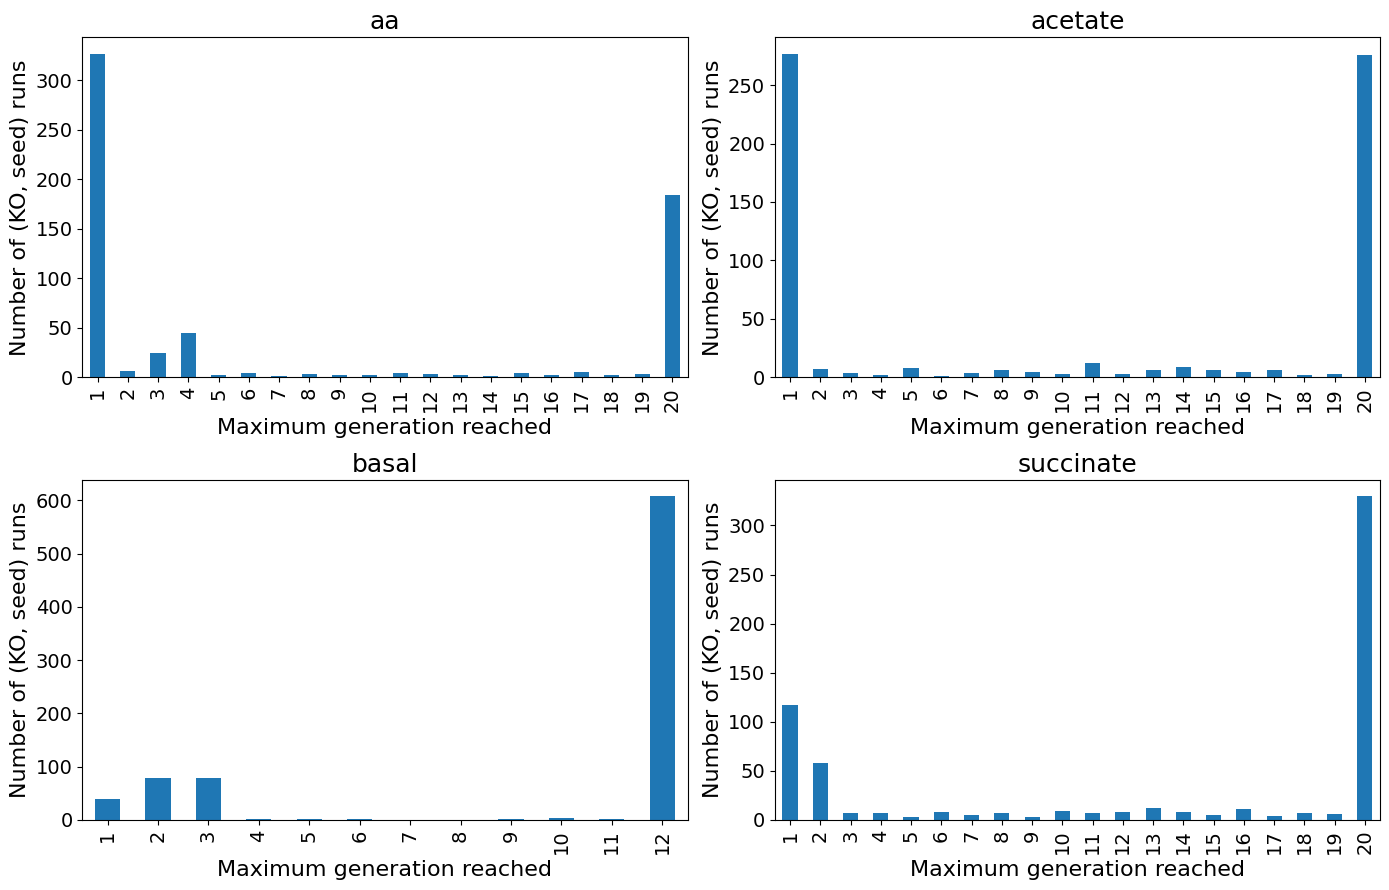

In [1]:
"""Step 0: Preliminary analysis"""
import pandas as pd, numpy as np

base = "/user/home/il22158/work/vEcoli/reading/results/growth_rate/"
files = {
    "basal":     "growth_rate_timeseries_gene_knockout_462KO_basal_all.parquet",
    "acetate":   "growth_rate_timeseries_gene_knockout_462KO_acetate_all.parquet",
    "succinate": "growth_rate_timeseries_gene_knockout_462KO_succinate_all.parquet",
    "aa":        "growth_rate_timeseries_gene_knockout_462KO_with_aa_all.parquet",
}
summary_files = {m: base + f.replace("timeseries", "summary").replace(".parquet", ".csv")
                 for m, f in files.items()}

GENE = "label"                 # e.g. "KO: EG10001"
SEED = "lineage_seed"
GEN  = "generation"
TIME = "time"
VAL  = "listeners__mass__instantaneous_growth_rate"
MASS = "listeners__mass__dry_mass"
MAX_GENERATION = {"basal": 12, "aa": 20, "acetate": 20, "succinate": 20}

dfs = {m: pd.read_parquet(base + f) for m, f in files.items()}
WILDTYPE = "baseline"
wildtype_files = [
    "growth_rate_timeseries_wildtype_3media_seed100_101_all.parquet",
    "growth_rate_timeseries_wildtype_with_aa_seed1_2_all.parquet",
]
wildtype_projects = {
    "wildtype_basal": "basal", "wildtype_acetate": "acetate",
    "wildtype_succinate": "succinate", "wildtype_with_aa_s1-5": "aa",
}
wt = pd.concat([pd.read_parquet(base + f) for f in wildtype_files], ignore_index=True)
if set(wt["project"]) != set(wildtype_projects) or set(wt[GENE]) != {WILDTYPE}:
    raise ValueError("Unexpected wildtype projects or labels")
wt["medium"] = wt["project"].map(wildtype_projects)
for m in dfs:
    if WILDTYPE in set(dfs[m][GENE]):
        raise ValueError(f"Wildtype label already present in {m} knockout data")
    w = wt[wt["medium"] == m].drop(columns="medium")
    expected_seeds = {1, 2} if m == "aa" else {100, 101}
    if set(w[SEED]) != expected_seeds:
        raise ValueError(f"Unexpected wildtype seeds in {m}: {sorted(w[SEED].unique())}")
    dfs[m] = pd.concat([dfs[m], w], ignore_index=True)

def seed_plot_values(per_seed):
    plot_values = per_seed.copy()
    aa_wt = (plot_values["medium"] == "aa") & (plot_values[GENE] == WILDTYPE)
    plot_values.loc[aa_wt, SEED] = plot_values.loc[aa_wt, SEED].map({1: 100, 2: 101})
    return plot_values

# Check 1: shape, dtypes, NaN/inf, time range per medium
rows = []
for m, d in dfs.items():
    v = d[VAL]
    rows.append({
        "medium": m,
        "n_rows": len(d),
        "n_gene": d[GENE].nunique(),
        "n_variant": d["variant"].nunique(),
        "n_seed": d[SEED].nunique(),
        "configured_max_generation": MAX_GENERATION[m],
        "max_generation_observed": d[GEN].max(),
        "n_nan": v.isna().sum(),
        "n_inf": np.isinf(v).sum(),
        "n_neg": (v < 0).sum(),
        "n_zero": (v == 0).sum(),   # includes the t=0 rows of each generation
        "t_min": d[TIME].min(),
        "t_max": d[TIME].max(),
        "gr_min": v.min(),
        "gr_median": v.median(),
        "gr_max": v.max(),
    })
print(pd.DataFrame(rows).set_index("medium").T)

# Summary files (one row per project, variant, and seed)
ko_summaries = {m: pd.read_csv(p) for m, p in summary_files.items()}
for m, s in ko_summaries.items():
    print(f"\n{m} summary:", s.shape)
    print(s.head(3))
wt_summaries = []
for f in wildtype_files:
    s = pd.read_csv(base + f.replace("timeseries", "summary").replace(".parquet", ".csv"))
    wt_summaries.append(s)
    print(f"\n{f} summary:")
    print(s)
wt_summary = pd.concat(wt_summaries, ignore_index=True)

# Combine usable growth-rate records and exclude constructed time-zero rows.
df = pd.concat([d.assign(medium=m) for m, d in dfs.items()], ignore_index=True)
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=[VAL])
df = df[df[TIME] > 0].copy()

raw = pd.concat([d.assign(medium=m) for m, d in dfs.items()], ignore_index=True)

# Audit the original jobs against current metadata; the additional AA seed is separate.
import sys, json
from pathlib import Path
from IPython.display import display
analysis_dir = "/user/home/il22158/work/slurm_logs/logs_analysis"
if analysis_dir not in sys.path:
    sys.path.insert(0, analysis_dir)
from analyze_growth_rate_4media import metadata_inventory, OUT
inventory = metadata_inventory()
inventory_rows = []
for m in ["basal", "acetate", "succinate", "aa"]:
    info = inventory[m]
    ko = ko_summaries[m]
    wt_project = next(p for p, medium in wildtype_projects.items() if medium == m)
    wt_metadata = json.loads((OUT / wt_project / "variant_sim_data" / "metadata.json").read_text(encoding="utf-8"))
    if list(wt_metadata["null"].values()) != [WILDTYPE]:
        raise ValueError(f"Unexpected baseline metadata in {wt_project}")
    baseline = wt_summary[wt_summary["project"] == wt_project]
    run_keys = ["project", "variant", SEED]
    for name, summary in [("KO", ko), ("baseline", baseline)]:
        if summary[run_keys].isna().any().any() or summary.duplicated(run_keys).any():
            raise ValueError(f"Missing or duplicate {name} run keys in {m} summary")
    if not baseline[GENE].eq(WILDTYPE).all() or ko[GENE].eq(WILDTYPE).any():
        raise ValueError(f"Unexpected labels in {m} summary")
    baseline_runs = len(baseline)
    inventory_rows.append({
        "medium": m,
        "original project folders": sum((OUT / p).is_dir() for p in info["projects"]),
        "KO variants with metadata": len(info["records"]),
        "metadata-backed KO runs": 2 * len(info["records"]),
        "KO runs in summary": len(ko),
        "baseline runs in summary": baseline_runs,
        "metadata-backed total including baseline": 2 * len(info["records"]) + 2,
    })
inventory_table = pd.DataFrame(inventory_rows).set_index("medium")
print("Original KO seeds 100/101; baseline seeds 100/101 (AA baseline 1/2).")
display(inventory_table)

raw["_t"] = raw[TIME].where((raw[TIME] > 0) & np.isfinite(raw[VAL]))  # NaN -> not counted as output
sim_status = (raw.groupby(["medium", GENE, SEED])
                .agg(n_output_timepoints=("_t", "nunique"), max_gen=(GEN, "max"))
                .reset_index())
sim_status["valid_run"] = sim_status["n_output_timepoints"] > 1
sim_status["target_max_gen"] = sim_status["medium"].map(MAX_GENERATION)
sim_status["reached_target_generation"] = sim_status["max_gen"] >= sim_status["target_max_gen"]
sim_status["division_outcome"] = np.where(
    sim_status["reached_target_generation"], "reached_target_generation", "did_not_reach_target_generation"
)
sim_status["run_status"] = np.where(sim_status["valid_run"], "valid_run", "invalid_run")
print("\nRun validity among runs with extracted rows (>1 distinct nonzero output time point):")
print(sim_status.assign(run_type=np.where(sim_status[GENE] == WILDTYPE, "baseline", "KO"))
      .groupby(["medium", "run_type"])["valid_run"].agg(valid_runs="sum", extracted_runs="size"))
print("\nGeneration outcome, reported separately from run validity:")
print(pd.crosstab(sim_status["medium"], sim_status["division_outcome"]))

# Generations actually reached per (knockout, seed)
for m, d in dfs.items():
    g = d.groupby([GENE, SEED])[GEN].max()
    print(f"\n{m}: max generation reached per (KO, seed)")
    print(g.value_counts().sort_index())

# Check 2: average over valid seeds, then one value per (medium, gene KO).
per_seed = (df.groupby(["medium", GENE, SEED])
              .agg(mean=(VAL, "mean"), n_output_timepoints=(TIME, "nunique")).reset_index())
per_seed["valid_run"] = per_seed["n_output_timepoints"] > 1
per_ko = (per_seed[per_seed["valid_run"]]
          .groupby(["medium", GENE])["mean"].mean().reset_index())

print(per_ko.groupby("medium")[GENE].nunique())
wide = per_ko.pivot(index=GENE, columns="medium", values="mean")
print("KOs missing per medium:\n", wide.isna().sum())
print(wide.describe())

# Visualization - Accumulated bar plot for distribution of maximum generation reached per (KO, seed) across media
import os, matplotlib.pyplot as plt
OUT0 = "/user/home/il22158/work/vEcoli/reading/results/pattern"
os.makedirs(OUT0, exist_ok=True)
gen_counts = sim_status[sim_status["valid_run"]].pivot_table(index="max_gen", columns="medium", values=SEED, aggfunc="size", fill_value=0)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, m in zip(axes.flat, gen_counts.columns):
    c = gen_counts[m].reindex(range(1, 13), fill_value=0) if m == "basal" else gen_counts[m]
    c.plot(kind="bar", ax=ax)
    ax.set_title(m, fontsize=18); ax.set_xlabel("Maximum generation reached", fontsize=16)
    ax.set_ylabel("Number of (KO, seed) runs", fontsize=16); ax.tick_params(labelsize=14)
plt.tight_layout(); plt.savefig(f"{OUT0}/step0_max_generation_stacked_bar.png", dpi=150); plt.show()

# File save - save the invalid/valid runs per KO, seed, media
sim_status.to_csv(f"{OUT0}/step0_run_status_per_KO_seed_media.csv", index=False)
inventory_table.to_csv(f"{OUT0}/step0_metadata_inventory.csv")


Simulation validity (>1 distinct nonzero output time point) and generation outcome:
           valid_runs  invalid_runs  valid_reaching_target  \
medium                                                       
aa                627            72                    184   
acetate           645            72                    276   
basal             814           112                    608   
succinate         622            62                    330   

           valid_below_target  total_runs  valid_run_fraction  
medium                                                         
aa                        443         699            0.896996  
acetate                   369         717            0.899582  
basal                     206         926            0.879050  
succinate                 292         684            0.909357  

Growth rate for 250 common KOs and wildtype (when present):
           count    median       IQR
medium                              
basal      250.0  0.7867

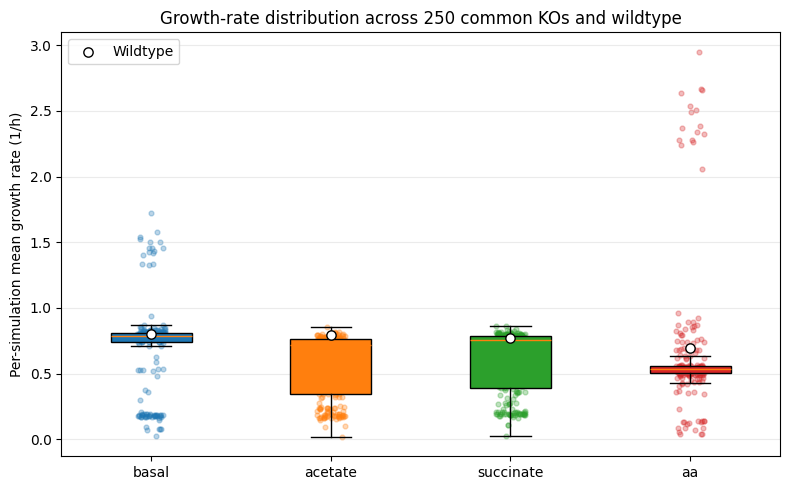

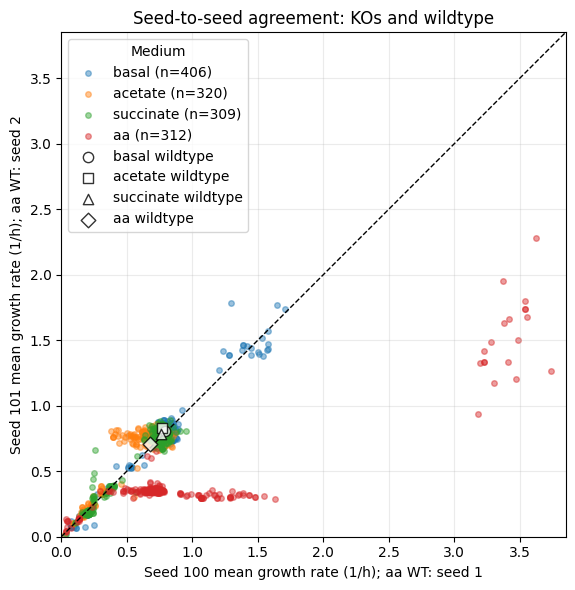

In [2]:
# Step 1a: per-KO growth patterns and seed agreement using all timepoints
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

OUT = "/user/home/il22158/work/vEcoli/reading/results/pattern"
os.makedirs(OUT, exist_ok=True)

medium_order = ["basal", "acetate", "succinate", "aa"]

# df contains finite growth-rate values at nonzero timepoints.
# Convert growth rate from 1/s to 1/h.
d = df.copy()
d[VAL] = d[VAL] * 3600

run_mean = (
    d.groupby(["medium", GENE, SEED])
     .agg(
         run_mean=(VAL, "mean"),
         n_run_points=(TIME, "nunique"),
     )
     .reset_index()
)

# Run validity is independent of whether the target generation was reached.
run_info = sim_status[
    ["medium", GENE, SEED, "n_output_timepoints", "max_gen"]
].copy()
run_info["valid_run"] = run_info["n_output_timepoints"] > 1
run_info["target_max_gen"] = run_info["medium"].map(MAX_GENERATION)
run_info["reached_target_generation"] = (
    run_info["max_gen"] >= run_info["target_max_gen"]
)
run_info["division_success"] = (
    run_info["valid_run"] & run_info["reached_target_generation"]
)

ps = run_info.merge(
    run_mean,
    on=["medium", GENE, SEED],
    how="left",
)
ps["n_run_points"] = ps["n_run_points"].fillna(0).astype(int)

missing_mean = ps["valid_run"] & ps["run_mean"].isna()
if missing_mean.any():
    raise ValueError("A valid simulation has no growth-rate data")

ps["mean"] = ps["run_mean"].where(ps["valid_run"])
ps["status"] = np.select(
    [~ps["valid_run"], ~ps["reached_target_generation"]],
    ["invalid_run", "did_not_reach_target_generation"],
    default="reached_target_generation",
)
ps.to_csv(f"{OUT}/step1a_per_seed_values.csv", index=False)

ps["valid_but_below_target"] = (
    ps["valid_run"] & ~ps["reached_target_generation"]
)
outcomes = ps.groupby("medium").agg(
    valid_runs=("valid_run", "sum"),
    invalid_runs=("valid_run", lambda x: (~x).sum()),
    valid_reaching_target=("division_success", "sum"),
    valid_below_target=("valid_but_below_target", "sum"),
    total_runs=("valid_run", "size"),
)
outcomes["valid_run_fraction"] = (
    outcomes["valid_runs"] / outcomes["total_runs"]
)
outcomes.to_csv(f"{OUT}/step1a_simulation_outcomes.csv")

print("Simulation validity (>1 distinct nonzero output time point) and generation outcome:")
print(outcomes)

ko_status = ps.groupby(["medium", GENE]).agg(
    n_seed_outputs=(SEED, "nunique"),
    n_valid_seeds=("valid_run", "sum"),
    n_division_successes=("division_success", "sum"),
    max_generation_reached=("max_gen", "max"),
    target_max_generation=("target_max_gen", "first"),
).reset_index()

ko_status["n_invalid_seeds"] = (
    ko_status["n_seed_outputs"] - ko_status["n_valid_seeds"]
)
ko_status["n_valid_seeds_below_target"] = (
    ko_status["n_valid_seeds"] - ko_status["n_division_successes"]
)
ko_status["status"] = np.select(
    [
        ko_status["n_valid_seeds"] == 0,
        ko_status["n_division_successes"] == ko_status["n_seed_outputs"],
        ko_status["n_division_successes"] == 0,
    ],
    [
        "no_valid_run",
        "all_seeds_reached_target",
        "no_seed_reached_target",
    ],
    default="mixed_outcome",
)
ko_status.to_csv(f"{OUT}/step1a_per_KO_simulation_status.csv", index=False)

# Average available valid-seed means within each KO and medium.
ko = (
    ps.groupby(["medium", GENE])["mean"]
      .mean()
      .reset_index()
)
ko.to_csv(f"{OUT}/step1a_per_KO_values.csv", index=False)

wide = ko.pivot(index=GENE, columns="medium", values="mean")
common = wide.reindex(columns=medium_order).dropna()
common.to_csv(f"{OUT}/step1a_per_KO_common_wide.csv")

summary = common.agg(["count", "median"]).T
summary["q1"] = common.quantile(0.25)
summary["q3"] = common.quantile(0.75)
summary["IQR"] = summary["q3"] - summary["q1"]
summary = summary[["count", "median", "IQR"]]
summary.to_csv(f"{OUT}/step1a_per_KO_summary.csv")

print(f"\nGrowth rate for {len(common)} common KOs and wildtype (when present):")
print(summary)

colors = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot(
    [common[m].to_numpy() for m in medium_order],
    tick_labels=medium_order,
    showfliers=False,
    patch_artist=True,
)
rng = np.random.default_rng(42)
for i, (patch, medium) in enumerate(
    zip(box["boxes"], medium_order),
    start=1,
):
    patch.set_facecolor(colors[i - 1])
    jitter = rng.uniform(-0.08, 0.08, len(common))
    ax.scatter(
        i + jitter,
        common[medium],
        color=colors[i - 1],
        s=12,
        alpha=0.3,
    )
    if WILDTYPE in common.index:
        ax.scatter(i, common.loc[WILDTYPE, medium], facecolor="white", edgecolor="black", s=45,
                   zorder=5, label="Wildtype" if i == 1 else None)

ax.set_ylabel("Per-simulation mean growth rate (1/h)")
ax.set_title(f"Growth-rate distribution across {len(common)} common KOs and wildtype")
if WILDTYPE in common.index:
    ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1a_per_KO_distribution.png", dpi=180)
plt.show()

seed_wide = seed_plot_values(ps).pivot_table(
    index=["medium", GENE],
    columns=SEED,
    values="mean",
)
seed_columns = seed_wide.columns.tolist()
if len(seed_columns) != 2:
    raise ValueError(f"Expected exactly 2 seeds, found {len(seed_columns)}")

seed_pairs = seed_wide.dropna()
fig, ax = plt.subplots(figsize=(6, 6))

for i, medium in enumerate(medium_order):
    if medium not in seed_pairs.index.get_level_values("medium"):
        print(f"{medium}: no KO has valid means for both seeds, so it is not plotted")
        continue

    pair = seed_pairs.xs(medium, level="medium").drop(index=WILDTYPE, errors="ignore")
    ax.scatter(
        pair[seed_columns[0]],
        pair[seed_columns[1]],
        color=colors[i],
        s=16,
        alpha=0.45,
        label=f"{medium} (n={len(pair)})",
    )

for medium, marker in zip(medium_order, ["o", "s", "^", "D"]):
    if (medium, WILDTYPE) in seed_pairs.index:
        pair = seed_pairs.loc[(medium, WILDTYPE)]
        ax.scatter(pair[seed_columns[0]], pair[seed_columns[1]], marker=marker, alpha = 0.8,
                   facecolor="white", edgecolor="black", s=55, zorder=5, label=f"{medium} wildtype")
low = min(0, seed_pairs[seed_columns].min().min())
high = seed_pairs[seed_columns].max().max()
high += 0.03 * (high - low)

ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
ax.set(
    xlim=(low, high),
    ylim=(low, high),
    xlabel=f"Seed {seed_columns[0]} mean growth rate (1/h); aa WT: seed 1",
    ylabel=f"Seed {seed_columns[1]} mean growth rate (1/h); aa WT: seed 2",
    title="Seed-to-seed agreement: KOs and wildtype",
)
ax.set_aspect("equal", adjustable="box")
ax.legend(title="Medium")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1a_seed_agreement.png", dpi=180)
plt.show()

Medium: basal, Window: (4, 11), Max generation for filter zero-growth: 11
Medium: acetate, Window: (3, 10), Max generation for filter zero-growth: 10
Medium: succinate, Window: (4, 11), Max generation for filter zero-growth: 11
Medium: aa, Window: (6, 13), Max generation for filter zero-growth: 13
Simulation validity (>1 distinct nonzero output time point) and generation outcome:
           valid_runs  invalid_runs  valid_reaching_target  \
medium                                                       
aa                627            72                    203   
acetate           645            72                    331   
basal             814           112                    609   
succinate         622            62                    398   

           valid_below_target  total_runs  valid_run_fraction  
medium                                                         
aa                        424         699            0.896996  
acetate                   314         717           

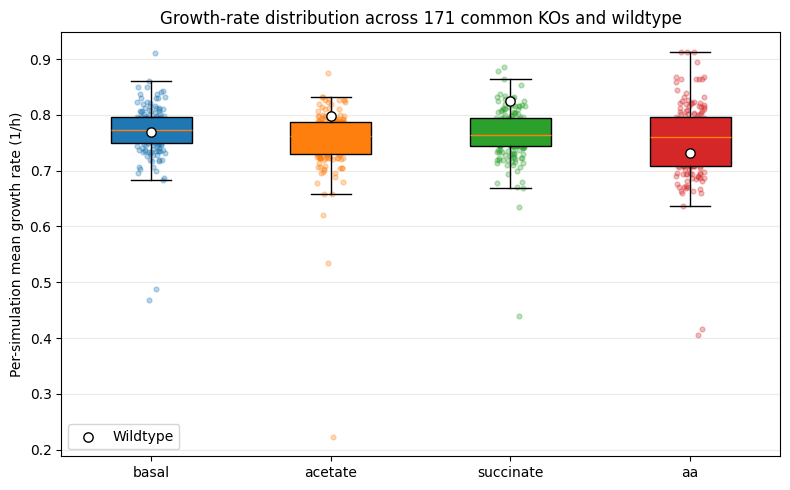

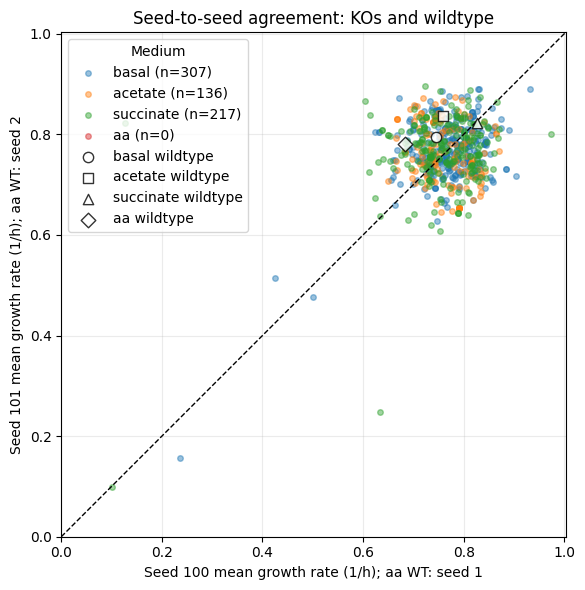

In [3]:
# Step 1b: per-KO growth patterns and seed agreement (growth rate in 1/h) with selected windows
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

OUT = "/user/home/il22158/work/vEcoli/reading/results/pattern"
os.makedirs(OUT, exist_ok=True)

WINDOWS_FILE = "/user/home/il22158/work/vEcoli/reading/results/tdi/tdi_summary_462KO_4media_composite_tdi.csv"
WINDOW_MEDIA = {"basal": "basal", "with_aa": "aa", "acetate": "acetate", "succinate": "succinate"}
medium_order = ["basal", "acetate", "succinate", "aa"]

window_table = pd.read_csv(WINDOWS_FILE)
window_table = window_table[window_table["Media"].isin(WINDOW_MEDIA)]
window_table["medium"] = window_table["Media"].map(WINDOW_MEDIA)
if window_table["medium"].isna().any():
    raise ValueError("TDI window file contains a medium not used in this analysis")
window_bounds = {}
for _, row in window_table.iterrows():
    start, end = map(int, row["Proposed generation window"].split("-"))
    window_bounds[row["medium"]] = (start, end)
if set(window_bounds) != set(medium_order):
    raise ValueError(f"Expected TDI windows for {medium_order}, found {sorted(window_bounds)}")
window_bounds["basal"] = (4, 11)
if set(df["medium"].unique()) != set(medium_order):
    raise ValueError(f"Unexpected input media: {sorted(df['medium'].unique())}")

d = df.copy()
d[VAL] = d[VAL] * 3600
d["window_start"] = d["medium"].map({m: bounds[0] for m, bounds in window_bounds.items()})
d["window_end"] = d["medium"].map({m: bounds[1] for m, bounds in window_bounds.items()})
MAX_GENERATION = {m: d.loc[d["medium"] == m, "window_end"].iloc[0] for m in medium_order}

for i in range(len(medium_order)):
    print(f"Medium: {medium_order[i]}, Window: {window_bounds[medium_order[i]]}, Max generation for filter zero-growth: {MAX_GENERATION[medium_order[i]]}")

in_window = d[(d[GEN] >= d["window_start"]) & (d[GEN] <= d["window_end"])]
window_mean = (in_window.groupby(["medium", GENE, SEED])
                 .agg(window_mean=(VAL, "mean"), n_window_points=(TIME, "nunique")).reset_index())

# Run validity comes from Step 0 (computed on the raw data, so runs with only t=0 rows are kept as invalid).
run_info = sim_status[["medium", GENE, SEED, "n_output_timepoints", "max_gen"]].copy()
run_info["valid_run"] = run_info["n_output_timepoints"] > 1
run_info["target_max_gen"] = run_info["medium"].map(MAX_GENERATION)
run_info["reached_target_generation"] = run_info["max_gen"] >= run_info["target_max_gen"]
run_info["division_success"] = run_info["valid_run"] & run_info["reached_target_generation"]
ps = run_info.merge(window_mean, on=["medium", GENE, SEED], how="left")
ps["n_window_points"] = ps["n_window_points"].fillna(0).astype(int)
missing_window = ps["division_success"] & ps["window_mean"].isna()
if missing_window.any():
    raise ValueError("A valid simulation reached its target generation but has no data in its proposed window")
# OPTIONAL (disabled): zero-fill valid runs that stop before the target generation
# ps["mean"] = np.where(
#     ~ps["valid_run"], np.nan,
#     np.where(ps["reached_target_generation"], ps["window_mean"], 0.0),
# )
ps["mean"] = ps["window_mean"].where(ps["valid_run"])
ps["status"] = np.select(
    [~ps["valid_run"], ~ps["reached_target_generation"]],
    ["invalid_run", "did_not_reach_target_generation"],
    default="reached_target_generation",
)
ps.to_csv(f"{OUT}/step1_per_seed_values.csv", index=False)

ps["valid_but_below_target"] = ps["valid_run"] & ~ps["reached_target_generation"]
outcomes = ps.groupby("medium").agg(
    valid_runs=("valid_run", "sum"),
    invalid_runs=("valid_run", lambda x: (~x).sum()),
    valid_reaching_target=("division_success", "sum"),
    valid_below_target=("valid_but_below_target", "sum"),
    total_runs=("valid_run", "size"),
)
outcomes["valid_run_fraction"] = outcomes["valid_runs"] / outcomes["total_runs"]
outcomes.to_csv(f"{OUT}/step1_simulation_outcomes.csv")
print("Simulation validity (>1 distinct nonzero output time point) and generation outcome:")
print(outcomes)

ko_status = ps.groupby(["medium", GENE]).agg(
    n_seed_outputs=(SEED, "nunique"),
    n_valid_seeds=("valid_run", "sum"),
    n_division_successes=("division_success", "sum"),
    max_generation_reached=("max_gen", "max"),
    target_max_generation=("target_max_gen", "first"),
).reset_index()
ko_status["n_invalid_seeds"] = ko_status["n_seed_outputs"] - ko_status["n_valid_seeds"]
ko_status["n_valid_seeds_below_target"] = ko_status["n_valid_seeds"] - ko_status["n_division_successes"]
ko_status["status"] = np.select(
    [ko_status["n_valid_seeds"] == 0,
     ko_status["n_division_successes"] == ko_status["n_seed_outputs"],
     ko_status["n_division_successes"] == 0],
    ["no_valid_run", "all_seeds_reached_target", "no_seed_reached_target"],
    default="mixed_outcome",
)
ko_status.to_csv(f"{OUT}/step1_per_KO_simulation_status.csv", index=False)

ko = ps.groupby(["medium", GENE])["mean"].mean().reset_index()
ko.to_csv(f"{OUT}/step1_per_KO_values.csv", index=False)

wide = ko.pivot(index=GENE, columns="medium", values="mean")
common = wide.reindex(columns=medium_order).dropna()
common.to_csv(f"{OUT}/step1_per_KO_common_wide.csv")

summary = common.agg(["count", "median"]).T
summary["q1"] = common.quantile(0.25)
summary["q3"] = common.quantile(0.75)
summary["IQR"] = summary["q3"] - summary["q1"]
summary = summary[["count", "median", "IQR"]]
summary.to_csv(f"{OUT}/step1_per_KO_summary.csv")
print(f"\nGrowth rate for {len(common)} common KOs and wildtype (when present):")
print(summary)

colors = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot(
    [common[m].to_numpy() for m in medium_order],
    tick_labels=medium_order,
    showfliers=False,
    patch_artist=True,
)
rng = np.random.default_rng(42)

for i, (patch, medium) in enumerate(zip(box["boxes"], medium_order), start=1):
    patch.set_facecolor(colors[i - 1])
    jitter = rng.uniform(-0.08, 0.08, len(common))
    ax.scatter(i + jitter, common[medium], color=colors[i - 1], s=12, alpha=0.3)
    if WILDTYPE in common.index:
        ax.scatter(i, common.loc[WILDTYPE, medium], facecolor="white", edgecolor="black", s=45,
                   zorder=5, label="Wildtype" if i == 1 else None)
ax.set_ylabel("Per-simulation mean growth rate (1/h)")
ax.set_title(f"Growth-rate distribution across {len(common)} common KOs and wildtype")
if WILDTYPE in common.index:
    ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1_per_KO_distribution.png", dpi=180)
plt.show()

seed_wide = seed_plot_values(ps).pivot_table(index=["medium", GENE], columns=SEED, values="mean")
seed_columns = seed_wide.columns.tolist()
if len(seed_columns) != 2:
    raise ValueError(f"Expected exactly 2 seeds, found {len(seed_columns)}")
seed_pairs = seed_wide.dropna()
fig, ax = plt.subplots(figsize=(6, 6))
for i, medium in enumerate(medium_order):
    if medium not in seed_pairs.index.get_level_values("medium"):
        print(f"{medium}: no KO has a window mean in both seeds, so it is not plotted")
        continue
    pair = seed_pairs.xs(medium, level="medium").drop(index=WILDTYPE, errors="ignore")
    ax.scatter(pair[seed_columns[0]], pair[seed_columns[1]], color=colors[i],
               s=16, alpha=0.45, label=f"{medium} (n={len(pair)})")
for medium, marker in zip(medium_order, ["o", "s", "^", "D"]):
    if (medium, WILDTYPE) in seed_pairs.index:
        pair = seed_pairs.loc[(medium, WILDTYPE)]
        ax.scatter(pair[seed_columns[0]], pair[seed_columns[1]], marker=marker, facecolor="white", edgecolor="black", alpha = 0.8,
                   s=55, zorder=5, label=f"{medium} wildtype")
low = min(0, seed_pairs[seed_columns].min().min())
high = seed_pairs[seed_columns].max().max()
high += 0.03 * (high - low)
ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
ax.set(xlim=(low, high), ylim=(low, high),
       xlabel=f"Seed {seed_columns[0]} mean growth rate (1/h); aa WT: seed 1",
       ylabel=f"Seed {seed_columns[1]} mean growth rate (1/h); aa WT: seed 2",
       title="Seed-to-seed agreement: KOs and wildtype")
ax.set_aspect("equal", adjustable="box")
ax.legend(title="Medium")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1_seed_agreement.png", dpi=180)

/tmp/ipykernel_3783535/2726913938.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


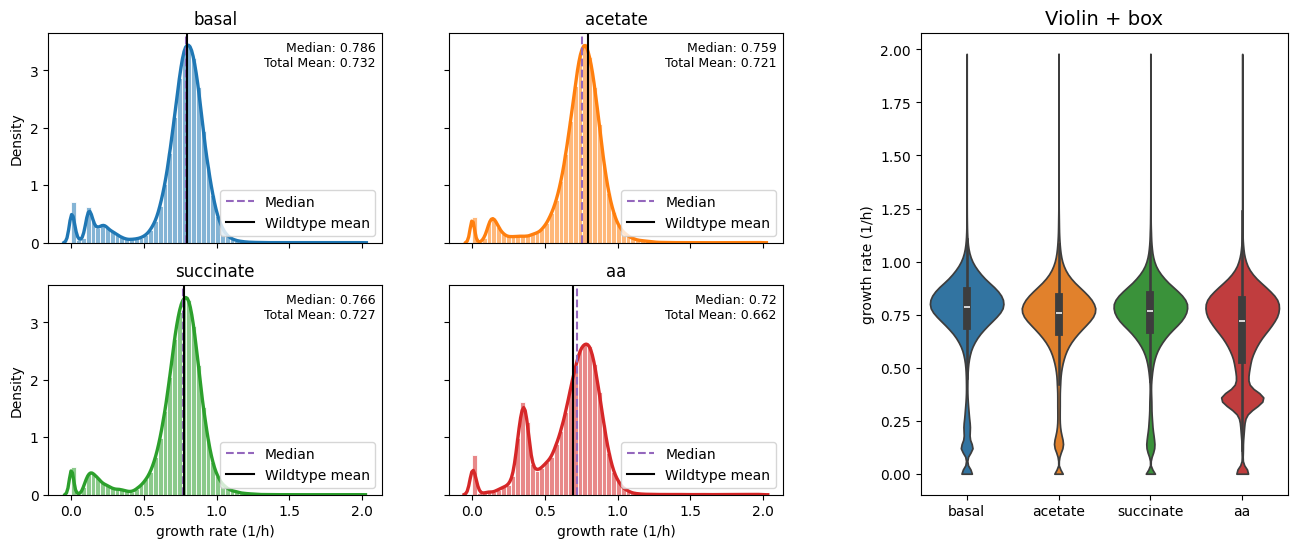

In [4]:
# Step 2: distribution of growth rate (1/h), all time points
# median point is indicated by a dashed line in the histograms
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

media = ["basal", "acetate", "succinate", "aa"]
palette = dict(zip(media, sns.color_palette("tab10", 4)))
LAB = "growth rate (1/h)"
central_line_color = sns.color_palette("tab10", 5)[-1]

# All time points (t > 0) of valid runs; trim rare extremes for plotting.
pts = d[d[TIME] > 0].merge(
    ps.loc[ps["valid_run"], ["medium", GENE, SEED]],
    on=["medium", GENE, SEED],
)
wildtype_mean = (pts[pts[GENE] == WILDTYPE].groupby(["medium", SEED])[VAL]
                 .mean().groupby("medium").mean())
lo, hi = pts[VAL].quantile([.005, .995])
pts = pts[(pts[VAL] >= lo) & (pts[VAL] <= hi)]
bin_edges = np.linspace(lo, hi, 61)

# Two main plots in one row: per-medium histograms on the left, violin plot on the right.
fig = plt.figure(figsize=(16, 6))
outer = fig.add_gridspec(1, 2, width_ratios=[2, 1], wspace=0.25)
hist_axes = outer[0, 0].subgridspec(2, 2).subplots(sharex=True, sharey=True)
violin_ax = fig.add_subplot(outer[0, 1])

for ax, medium in zip(hist_axes.flat, media):
    medium_pts = pts[pts["medium"] == medium]
    median = medium_pts[VAL].median()
    mean = medium_pts[VAL].mean()

    sns.histplot(
        data=medium_pts,
        x=VAL,
        bins=bin_edges,
        stat="density",
        element="bars",
        fill=True,
        alpha=0.55,
        color=palette[medium],
        edgecolor="white",
        linewidth=0.6,
        ax=ax,
    )
    sns.kdeplot(
        data=medium_pts,
        x=VAL,
        color=palette[medium],
        linewidth=2.4,
        ax=ax,
    )

    ax.axvline(median, color=central_line_color, linestyle="--", linewidth=1.5, label="Median")
    if medium in wildtype_mean.index:
        ax.axvline(wildtype_mean[medium], color="black", linewidth=1.5, label="Wildtype mean")
        ax.legend(loc="lower right")
    ax.text(
        0.98, 0.96, f"Median: {median:.3g}\nTotal Mean: {mean:.3g}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
    ax.set_title(medium)
    ax.set_xlabel(LAB)
    ax.set_ylabel("Density")

sns.violinplot(
    data=pts,
    x="medium",
    y=VAL,
    order=media,
    hue="medium",
    hue_order=media,
    palette=palette,
    legend=False,
    inner="box",
    cut=0,
    ax=violin_ax,
)
violin_ax.set_title("Violin + box", fontsize=14)
violin_ax.set_ylabel(LAB)
violin_ax.set_xlabel("")

fig.tight_layout()
fig.savefig(f"{OUT}/step2_timepoints_all.png", dpi=200, bbox_inches="tight")
plt.show()

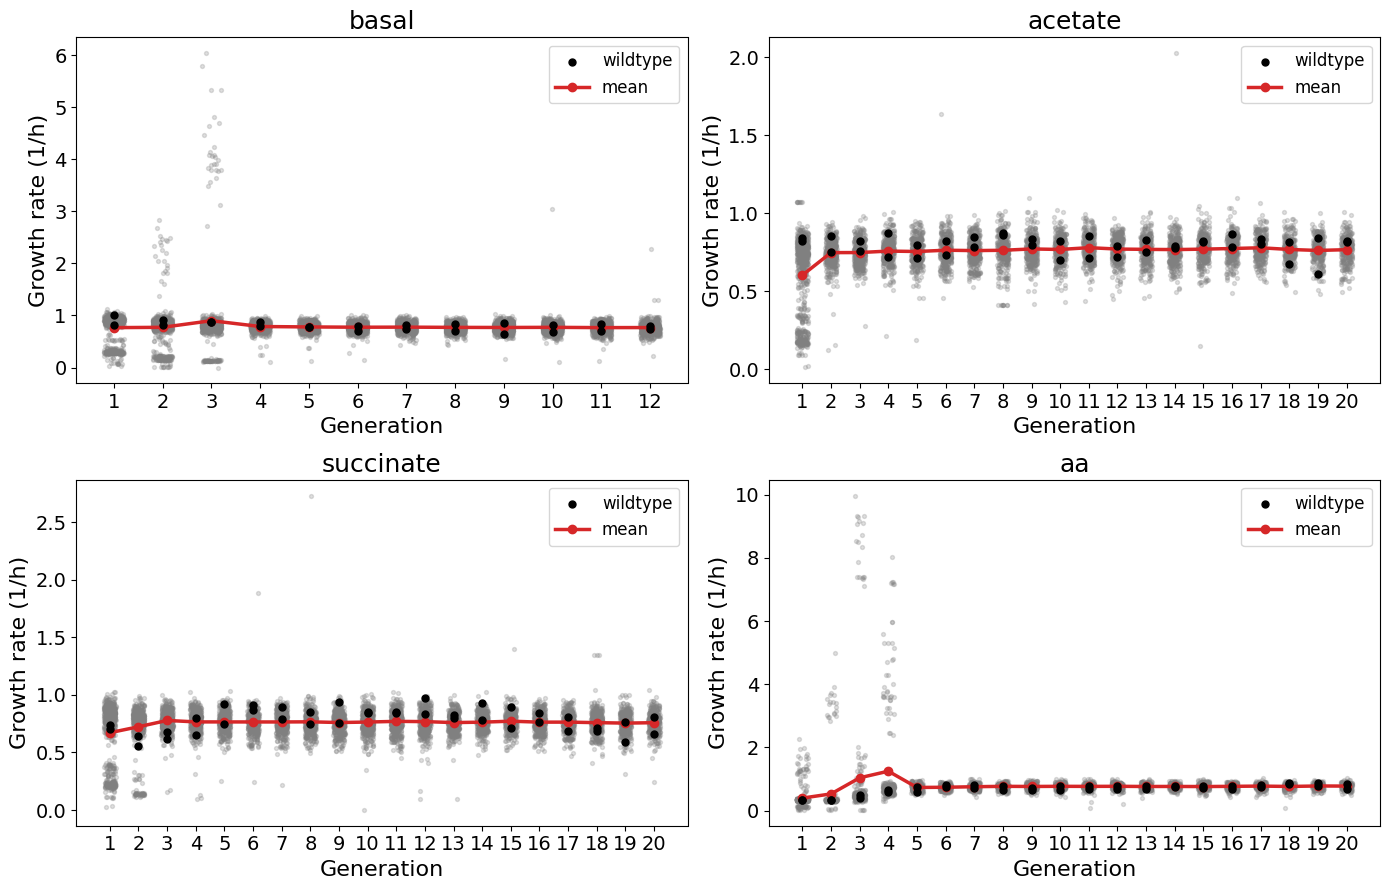

In [5]:
# Step 3: temporal pattern, growth rate (1/h) averaged within each generation
# One point per (KO, seed, generation) from valid runs; the line is the mean over those points.
MAX_GEN_PLOT = {"basal": 12, "acetate": 20, "succinate": 20, "aa": 20}
tp = d[d[TIME] > 0].merge(ps.loc[ps["valid_run"], ["medium", GENE, SEED]], on=["medium", GENE, SEED])
gen_mean = tp.groupby(["medium", GENE, SEED, GEN])[VAL].mean().reset_index(name="gen_mean")
gen_mean = gen_mean[gen_mean[GEN] <= gen_mean["medium"].map(MAX_GEN_PLOT)]
line = gen_mean.groupby(["medium", GEN])["gen_mean"].agg(mean="mean", n_runs="size").reset_index()
line.to_csv(f"{OUT}/step3_generation_mean_growth_rate.csv", index=False)

rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, m in zip(axes.flat, ["basal", "acetate", "succinate", "aa"]):
    g = gen_mean[gen_mean["medium"] == m]
    ko_g = g[g[GENE] != WILDTYPE]
    wt_g = g[g[GENE] == WILDTYPE]
    ax.scatter(ko_g[GEN] + rng.uniform(-0.2, 0.2, len(ko_g)), ko_g["gen_mean"], s=8, alpha=0.25, color="grey")
    ax.scatter(wt_g[GEN], wt_g["gen_mean"], s=25, color="black", zorder=5, label="wildtype")
    l = line[line["medium"] == m]
    ax.plot(l[GEN], l["mean"], color="C3", lw=2.5, marker="o", label="mean")
    ax.set_xticks(range(1, MAX_GEN_PLOT[m] + 1))
    ax.set_title(m, fontsize=18)
    ax.set_xlabel("Generation", fontsize=16)
    ax.set_ylabel("Growth rate (1/h)", fontsize=16)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12)
plt.tight_layout()
plt.savefig(f"{OUT}/step3_temporal_pattern.png", dpi=200, bbox_inches="tight")
plt.show()


# Phase-2 Plan

**Goal:** quantify how media and gene knockouts jointly affect growth rate, and identify the KOs with the largest effects in each medium.

Two methods to compare with baseline (wildtype, basal condition): 1. substution, 2. log(targe/baseline).

1. **Data and preprocessing:** reuse the Phase-1 summary CSVs and growth-rate time-series parquet files for basal, acetate, succinate, and AA, including wildtype. Exclude AA seed 101 due to known errors. Ignore generation windows; calculate each valid run's mean over all available finite nonzero-time points and convert from 1/s to 1/h. Use the summary files to report missing runs and generations reached; do not treat early termination as failure or fill missing values with zero.
2. **Growth and KO effects:** average available seed-level means equally for each medium and KO. Compare each KO with the wildtype mean in the same medium (KO minus wildtype); rank the largest decreases and increases separately. Report seed counts and seed-level variation, and flag incomplete conditions.
3. **Media–KO interaction:** use basal as the reference and calculate, for each KO and other medium, `(KO − wildtype in medium) − (KO − wildtype in basal)`. Nonzero contrasts indicate that the KO effect depends on medium; describe these as deviations from additivity, not proof of biological synergy. Compare only observed conditions, report missing combinations, and assess sensitivity to seed variation; wildtype and KO seeds are not assumed paired.
4. **Visualization and outputs:** plot a 3D categorical scatter with medium and gene KO on the x/y axes and mean growth rate on z, highlighting wildtype. Add a medium-by-KO heatmap of interaction contrasts and per-medium ranked KO-effect plots. Export the per-condition growth, KO-effect and interaction tables with replicate counts; summarize the strongest effects and interactions. Interpret results cautiously because there are only two seeds and runs may cover different durations.

# Phase-2 Code

In [6]:
# Phase 2, Step 1: all-time-point run means and data availability
# Run Phase 1's preliminary analysis cell first (df, sim_status and summaries).
run_keys = ["medium", GENE, SEED]
summary = pd.concat(
    [s.assign(medium=m) for m, s in ko_summaries.items()]
    + [wt_summary.assign(medium=wt_summary["project"].map(wildtype_projects))],
    ignore_index=True,
)
if summary[run_keys].isna().any().any() or summary.duplicated(run_keys).any():
    raise ValueError("Missing or duplicate medium/KO/seed keys in summary data")

# Phase 1 excludes non-finite growth rates and constructed time-zero rows.
run_means = (
    df.groupby(run_keys)[VAL].mean().mul(3600)
    .reset_index(name="mean_growth_rate_per_hour")
)
phase2_runs = sim_status[run_keys + ["n_output_timepoints", "max_gen", "valid_run"]].merge(
    run_means, on=run_keys, how="left", validate="one_to_one"
)
phase2_runs.loc[~phase2_runs["valid_run"], "mean_growth_rate_per_hour"] = np.nan
phase2_runs = summary[run_keys + ["max_generation"]].merge(
    phase2_runs, on=run_keys, how="outer", indicator="data_availability", validate="one_to_one"
)
excluded_aa_seed = (phase2_runs["medium"] == "aa") & (phase2_runs[SEED] == 101)
print(f"Excluded {excluded_aa_seed.sum()} AA seed-101 runs due to known errors.")
phase2_runs = phase2_runs.loc[~excluded_aa_seed].copy()
phase2_runs["run_type"] = np.where(phase2_runs[GENE] == WILDTYPE, "wildtype", "KO")
print("Run availability (left_only: summary only; right_only: time series only):")
display(phase2_runs.groupby(["medium", "run_type", "data_availability"], observed=True).size().unstack(fill_value=0))

# Candidate KO combinations absent from both files are not necessarily failed or submitted runs.
ko_labels = phase2_runs.loc[phase2_runs[GENE] != WILDTYPE, [GENE]].drop_duplicates()
candidate_runs = ko_labels.merge(pd.DataFrame({"medium": list(ko_summaries)}), how="cross")
candidate_runs = candidate_runs.merge(pd.DataFrame({SEED: [100, 101]}), how="cross")
candidate_runs = candidate_runs.loc[~((candidate_runs["medium"] == "aa") & (candidate_runs[SEED] == 101))]
phase2_missing_runs = candidate_runs.merge(
    phase2_runs[run_keys], on=run_keys, how="left", indicator=True, validate="one_to_one"
).query("_merge == 'left_only'").drop(columns="_merge")
print("KO/seed combinations absent from both files (excluding AA seed 101):")
display(phase2_missing_runs.groupby("medium").size().reindex(list(ko_summaries), fill_value=0))
print("Maximum generations reached in the summary files:")
display(phase2_runs.groupby(["medium", "max_generation"]).size().unstack(fill_value=0))
print("Run-level growth means and generation details:")
display(phase2_runs.head())

Excluded 348 AA seed-101 runs due to known errors.
Run availability (left_only: summary only; right_only: time series only):


data_availability   both
medium    run_type      
aa        KO         349
          wildtype     2
acetate   KO         715
          wildtype     2
basal     KO         924
          wildtype     2
succinate KO         682
          wildtype     2

KO/seed combinations absent from both files (excluding AA seed 101):


medium
basal          0
acetate      209
succinate    242
aa           113
dtype: int64

Maximum generations reached in the summary files:


max_generation,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
medium,,,,,,,,,,,,,,,,,,,,
aa,51,6,25,45,2,4,1,3,2,2,4,3,2,1,4,2,5,2,3,184
acetate,349,7,4,2,8,1,4,6,5,3,12,3,6,9,6,5,6,2,3,276
basal,152,78,79,2,1,1,0,0,1,3,1,608,0,0,0,0,0,0,0,0
succinate,179,58,7,7,3,8,5,7,3,9,7,8,12,8,5,11,4,7,6,330


Run-level growth means and generation details:


,medium,label,lineage_seed,max_generation,n_output_timepoints,max_gen,valid_run,mean_growth_rate_per_hour,data_availability,run_type
0,aa,KO: EG10001,100,20,1143,20,True,0.683404,both,KO
2,aa,KO: EG10004,100,20,1096,20,True,0.720215,both,KO
4,aa,KO: EG10006,100,20,1126,20,True,0.706789,both,KO
6,aa,KO: EG10007,100,20,1134,20,True,0.688294,both,KO
8,aa,KO: EG10012,100,20,1242,20,True,0.631258,both,KO


In [7]:
# Phase 2, Step 2: per-condition growth and KO effects relative to wildtype
condition_keys = ["medium", GENE]
condition_grid = pd.concat([
    candidate_runs[condition_keys],
    phase2_runs.loc[phase2_runs[GENE] == WILDTYPE, condition_keys],
], ignore_index=True).drop_duplicates()
growth = phase2_runs.groupby(condition_keys)["mean_growth_rate_per_hour"].agg(
    mean_growth_rate="mean", n_valid_seeds="count", seed_sd="std"
).reset_index()
phase2_growth = condition_grid.merge(growth, on=condition_keys, how="left", validate="one_to_one")
phase2_growth["n_valid_seeds"] = phase2_growth["n_valid_seeds"].fillna(0).astype(int)
# Flag fewer than the original two seeds, including the excluded AA KO seed 101.
phase2_growth["incomplete"] = phase2_growth["n_valid_seeds"] < 2

wildtype = phase2_growth.loc[phase2_growth[GENE] == WILDTYPE, [
    "medium", "mean_growth_rate", "n_valid_seeds", "seed_sd", "incomplete"
]].rename(columns={
    "mean_growth_rate": "wildtype_mean_growth_rate",
    "n_valid_seeds": "wildtype_n_valid_seeds",
    "seed_sd": "wildtype_seed_sd",
    "incomplete": "wildtype_incomplete",
})
phase2_effects = phase2_growth.loc[phase2_growth[GENE] != WILDTYPE].merge(
    wildtype, on="medium", how="left", validate="many_to_one"
)
phase2_effects["wildtype_incomplete"] = phase2_effects["wildtype_incomplete"].fillna(True)
phase2_effects["effect_vs_wildtype"] = (
    phase2_effects["mean_growth_rate"] - phase2_effects["wildtype_mean_growth_rate"]
)
phase2_effects["comparison_incomplete"] = (
    phase2_effects["incomplete"] | phase2_effects["wildtype_incomplete"]
)

measured_effects = phase2_effects.dropna(subset=["effect_vs_wildtype"])
largest_decreases = (measured_effects[measured_effects["effect_vs_wildtype"] < 0]
    .sort_values("effect_vs_wildtype").groupby("medium", sort=False).head(5))
largest_increases = (measured_effects[measured_effects["effect_vs_wildtype"] > 0]
    .sort_values("effect_vs_wildtype", ascending=False).groupby("medium", sort=False).head(5))
display_columns = ["medium", GENE, "effect_vs_wildtype", "n_valid_seeds", "seed_sd", "comparison_incomplete"]
ranked_effects = pd.concat({"decrease": largest_decreases[display_columns], "increase": largest_increases[display_columns]}, names=["direction"])
phase2_effects.to_csv(
    "/user/home/il22158/work/vEcoli/reading/results/pattern/phase2_step2_KO_effect.csv", index=False
)
display(ranked_effects)

medium        label  effect_vs_wildtype  n_valid_seeds  \
direction                                                                   
decrease  681     acetate  KO: EG10774           -0.780412              2   
          680       basal  KO: EG10774           -0.776281              2   
          682   succinate  KO: EG10774           -0.743290              2   
          728       basal  KO: EG10807           -0.724061              2   
          488       basal  KO: EG10420           -0.721350              2   
          492       basal  KO: EG10421           -0.721350              2   
          736       basal  KO: EG10810           -0.718004              2   
          661     acetate  KO: EG10755           -0.705206              2   
          697     acetate  KO: EG10792           -0.700091              2   
          1441    acetate  KO: EG10795           -0.700091              2   
          662   succinate  KO: EG10755           -0.666522              2   
          1442  succinate  KO: EG10795           -0.662476              2   
          698   succinate  KO: EG10792           -0.662476              2   
          739          aa  KO: EG10810           -0.661111              1   
          491          aa  KO: EG10420           -0.660054              1   
          495          aa  KO: EG10421           -0.660054              1   
          743          aa  KO: EG10811           -0.656943              1   
          1433    acetate  KO: EG10586           -0.656820              2   
          823          aa  KO: EG10894           -0.655058              1   
          594   succinate  KO: EG10581           -0.605832              2   
increase  927          aa  KO: EG11067            3.042808              1   
          383          aa  KO: EG10196            2.928733              1   
          919          aa  KO: EG11043            2.860613              1   
          655          aa  KO: EG10710            2.846089              1   
          651          aa  KO: EG10709            2.846089              1   
          528       basal  KO: EG10453            0.928590              2   
          1508      basal  KO: EG11030            0.912219              2   
          380       basal  KO: EG10196            0.778841              2   
          540       basal  KO: EG10492            0.744571              2   
          916       basal  KO: EG11043            0.727050              2   
          1594  succinate    KO: G7454            0.108007              2   
          1382  succinate    KO: G7533            0.088361              2   
          1370  succinate    KO: G7486            0.087277              2   
          1738  succinate    KO: G7542            0.074850              2   
          126   succinate  KO: EG10058            0.067814              2   
          1393    acetate    KO: G7579            0.055723              1   
          1601    acetate    KO: G7530            0.030867              1   
          933     acetate  KO: EG11112            0.030275              2   
          1       acetate  KO: EG10001            0.021162              2   
          1037    acetate  KO: EG11810            0.016581              2   

                 seed_sd  comparison_incomplete  
direction                                        
decrease  681   0.007379                  False  
          680   0.009857                  False  
          682   0.008838                  False  
          728   0.001321                  False  
          488   0.000805                  False  
          492   0.000805                  False  
          736   0.019629                  False  
          661   0.003468                  False  
          697   0.010470                  False  
          1441  0.010470                  False  
          662   0.001721                  False  
          1442  0.000447                  False  
          698   0.000447                  False  
          739        NaN          

In [8]:
# Phase 2, Step 3: media-KO interaction relative to basal
basal_effects = phase2_effects.loc[phase2_effects["medium"] == "basal", [
    GENE, "effect_vs_wildtype", "n_valid_seeds", "wildtype_n_valid_seeds", "comparison_incomplete"
]].rename(columns={
    "effect_vs_wildtype": "basal_effect",
    "n_valid_seeds": "basal_n_valid_seeds",
    "wildtype_n_valid_seeds": "basal_wildtype_n_valid_seeds",
    "comparison_incomplete": "basal_comparison_incomplete",
})
phase2_interactions = phase2_effects.loc[phase2_effects["medium"] != "basal"].merge(
    basal_effects, on=GENE, how="left", validate="many_to_one"
)
phase2_interactions["interaction"] = (
    phase2_interactions["effect_vs_wildtype"] - phase2_interactions["basal_effect"]
)
phase2_interactions["interaction_incomplete"] = (
    phase2_interactions["comparison_incomplete"]
    | phase2_interactions["basal_comparison_incomplete"].fillna(True)
)

# Sensitivity range: combine seed extrema independently, not a confidence interval.
# A single available seed gives no information about that condition's variability.
seed_range = phase2_runs.groupby(["medium", GENE])["mean_growth_rate_per_hour"].agg(
    seed_min="min", seed_max="max"
).reset_index()
wt_range = seed_range.loc[seed_range[GENE] == WILDTYPE, ["medium", "seed_min", "seed_max"]]
effect_range = seed_range.loc[seed_range[GENE] != WILDTYPE].merge(
    wt_range, on="medium", how="left", suffixes=("_ko", "_wt"), validate="many_to_one"
)
effect_range["effect_min"] = effect_range["seed_min_ko"] - effect_range["seed_max_wt"]
effect_range["effect_max"] = effect_range["seed_max_ko"] - effect_range["seed_min_wt"]
effect_range = effect_range[["medium", GENE, "effect_min", "effect_max"]]
basal_range = effect_range.loc[effect_range["medium"] == "basal", [GENE, "effect_min", "effect_max"]].rename(
    columns={"effect_min": "basal_effect_min", "effect_max": "basal_effect_max"}
)
phase2_interactions = phase2_interactions.merge(effect_range, on=["medium", GENE], how="left", validate="one_to_one")
phase2_interactions = phase2_interactions.merge(basal_range, on=GENE, how="left", validate="many_to_one")
phase2_interactions["interaction_min"] = phase2_interactions["effect_min"] - phase2_interactions["basal_effect_max"]
phase2_interactions["interaction_max"] = phase2_interactions["effect_max"] - phase2_interactions["basal_effect_min"]

phase2_interactions.to_csv(
    "/user/home/il22158/work/vEcoli/reading/results/pattern/phase2_step3_interactions.csv", index=False
)
availability = phase2_interactions.groupby("medium")["interaction"].agg(
    observed="count", total="size"
)
availability["missing"] = availability["total"] - availability["observed"]
display(availability)
strongest = phase2_interactions.dropna(subset=["interaction"]).assign(
    magnitude=lambda x: x["interaction"].abs()
).sort_values("magnitude", ascending=False).groupby("medium", sort=False).head(5)
display(strongest[["medium", GENE, "interaction", "interaction_min", "interaction_max", "interaction_incomplete"]])

,observed,total,missing
medium,,,
aa,313,462,149
acetate,323,462,139
succinate,311,462,151


,medium,label,interaction,interaction_min,interaction_max,interaction_incomplete
695,aa,KO: EG11067,2.398091,2.370705,2.425476,True
488,aa,KO: EG10709,2.219486,2.158087,2.280884,True
491,aa,KO: EG10710,2.219486,2.158087,2.280884,True
356,aa,KO: EG10407,2.169412,2.124617,2.214206,True
287,aa,KO: EG10196,2.149892,2.123529,2.176255,True
396,acetate,KO: EG10453,-1.479384,-1.539162,-1.419606,False
1131,acetate,KO: EG11030,-1.458092,-1.564284,-1.351901,False
285,acetate,KO: EG10196,-1.333412,-1.389152,-1.277673,False
405,acetate,KO: EG10492,-1.303033,-1.592717,-1.013349,False
286,succinate,KO: EG10196,-1.283871,-1.327966,-1.239777,False


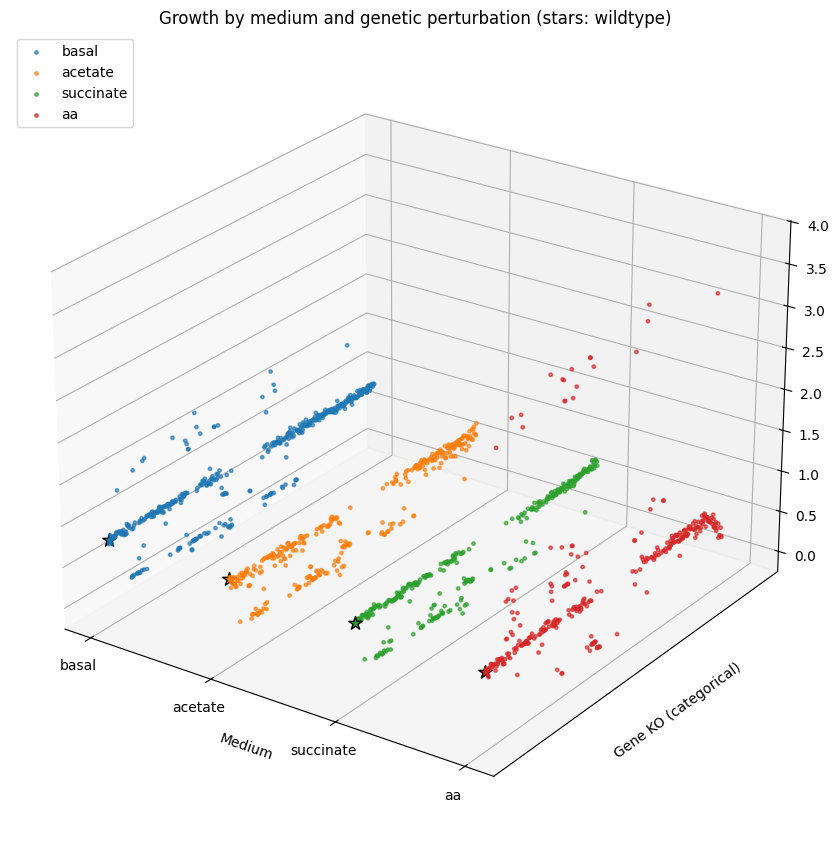

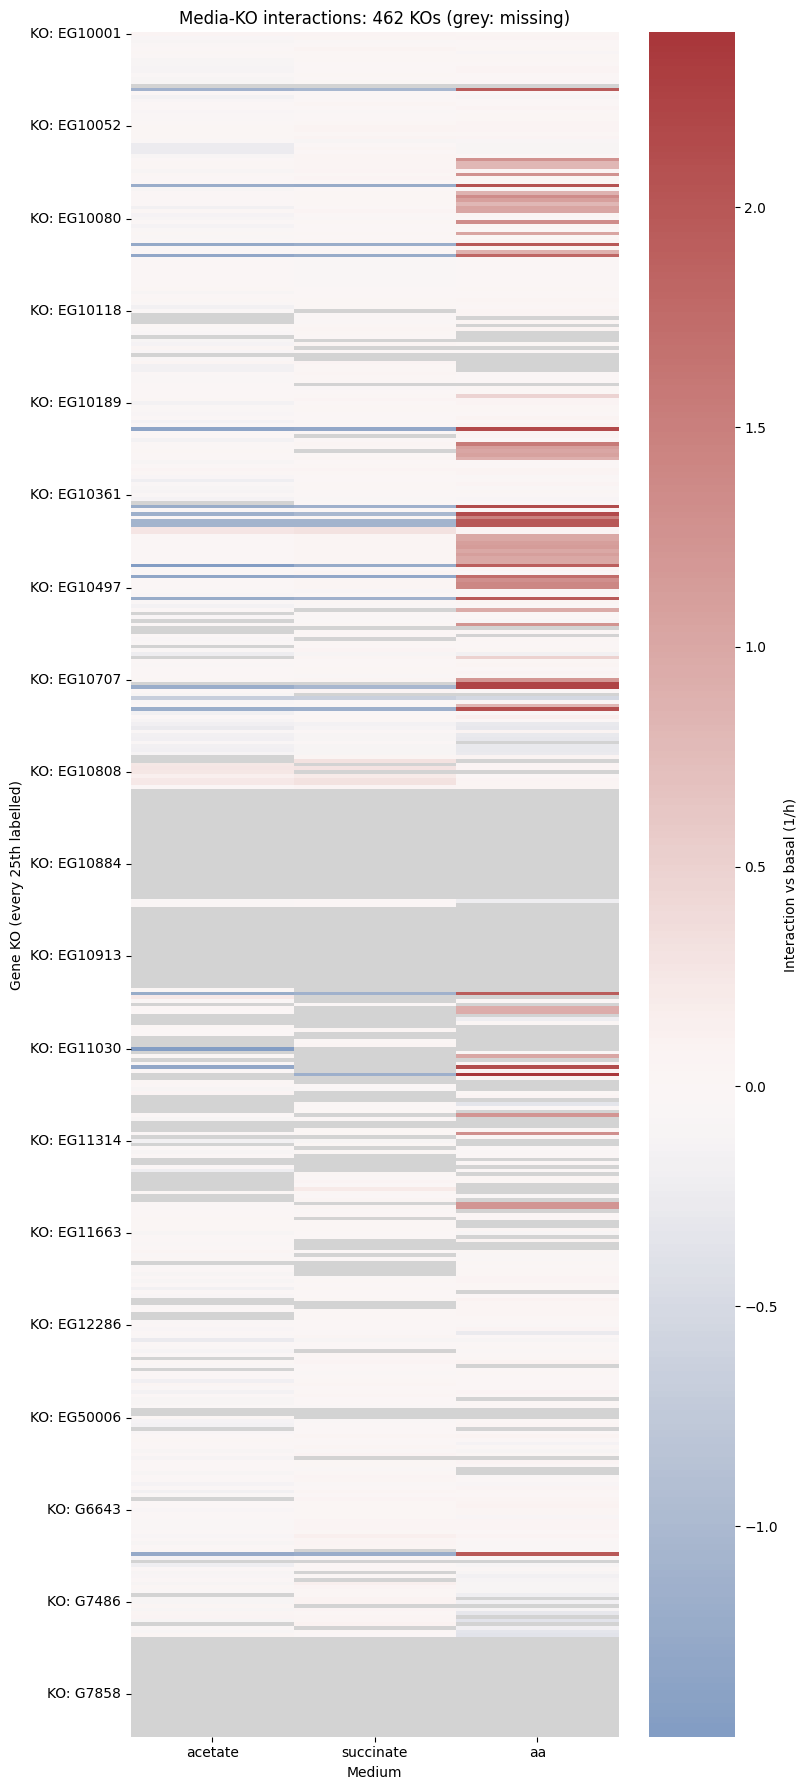

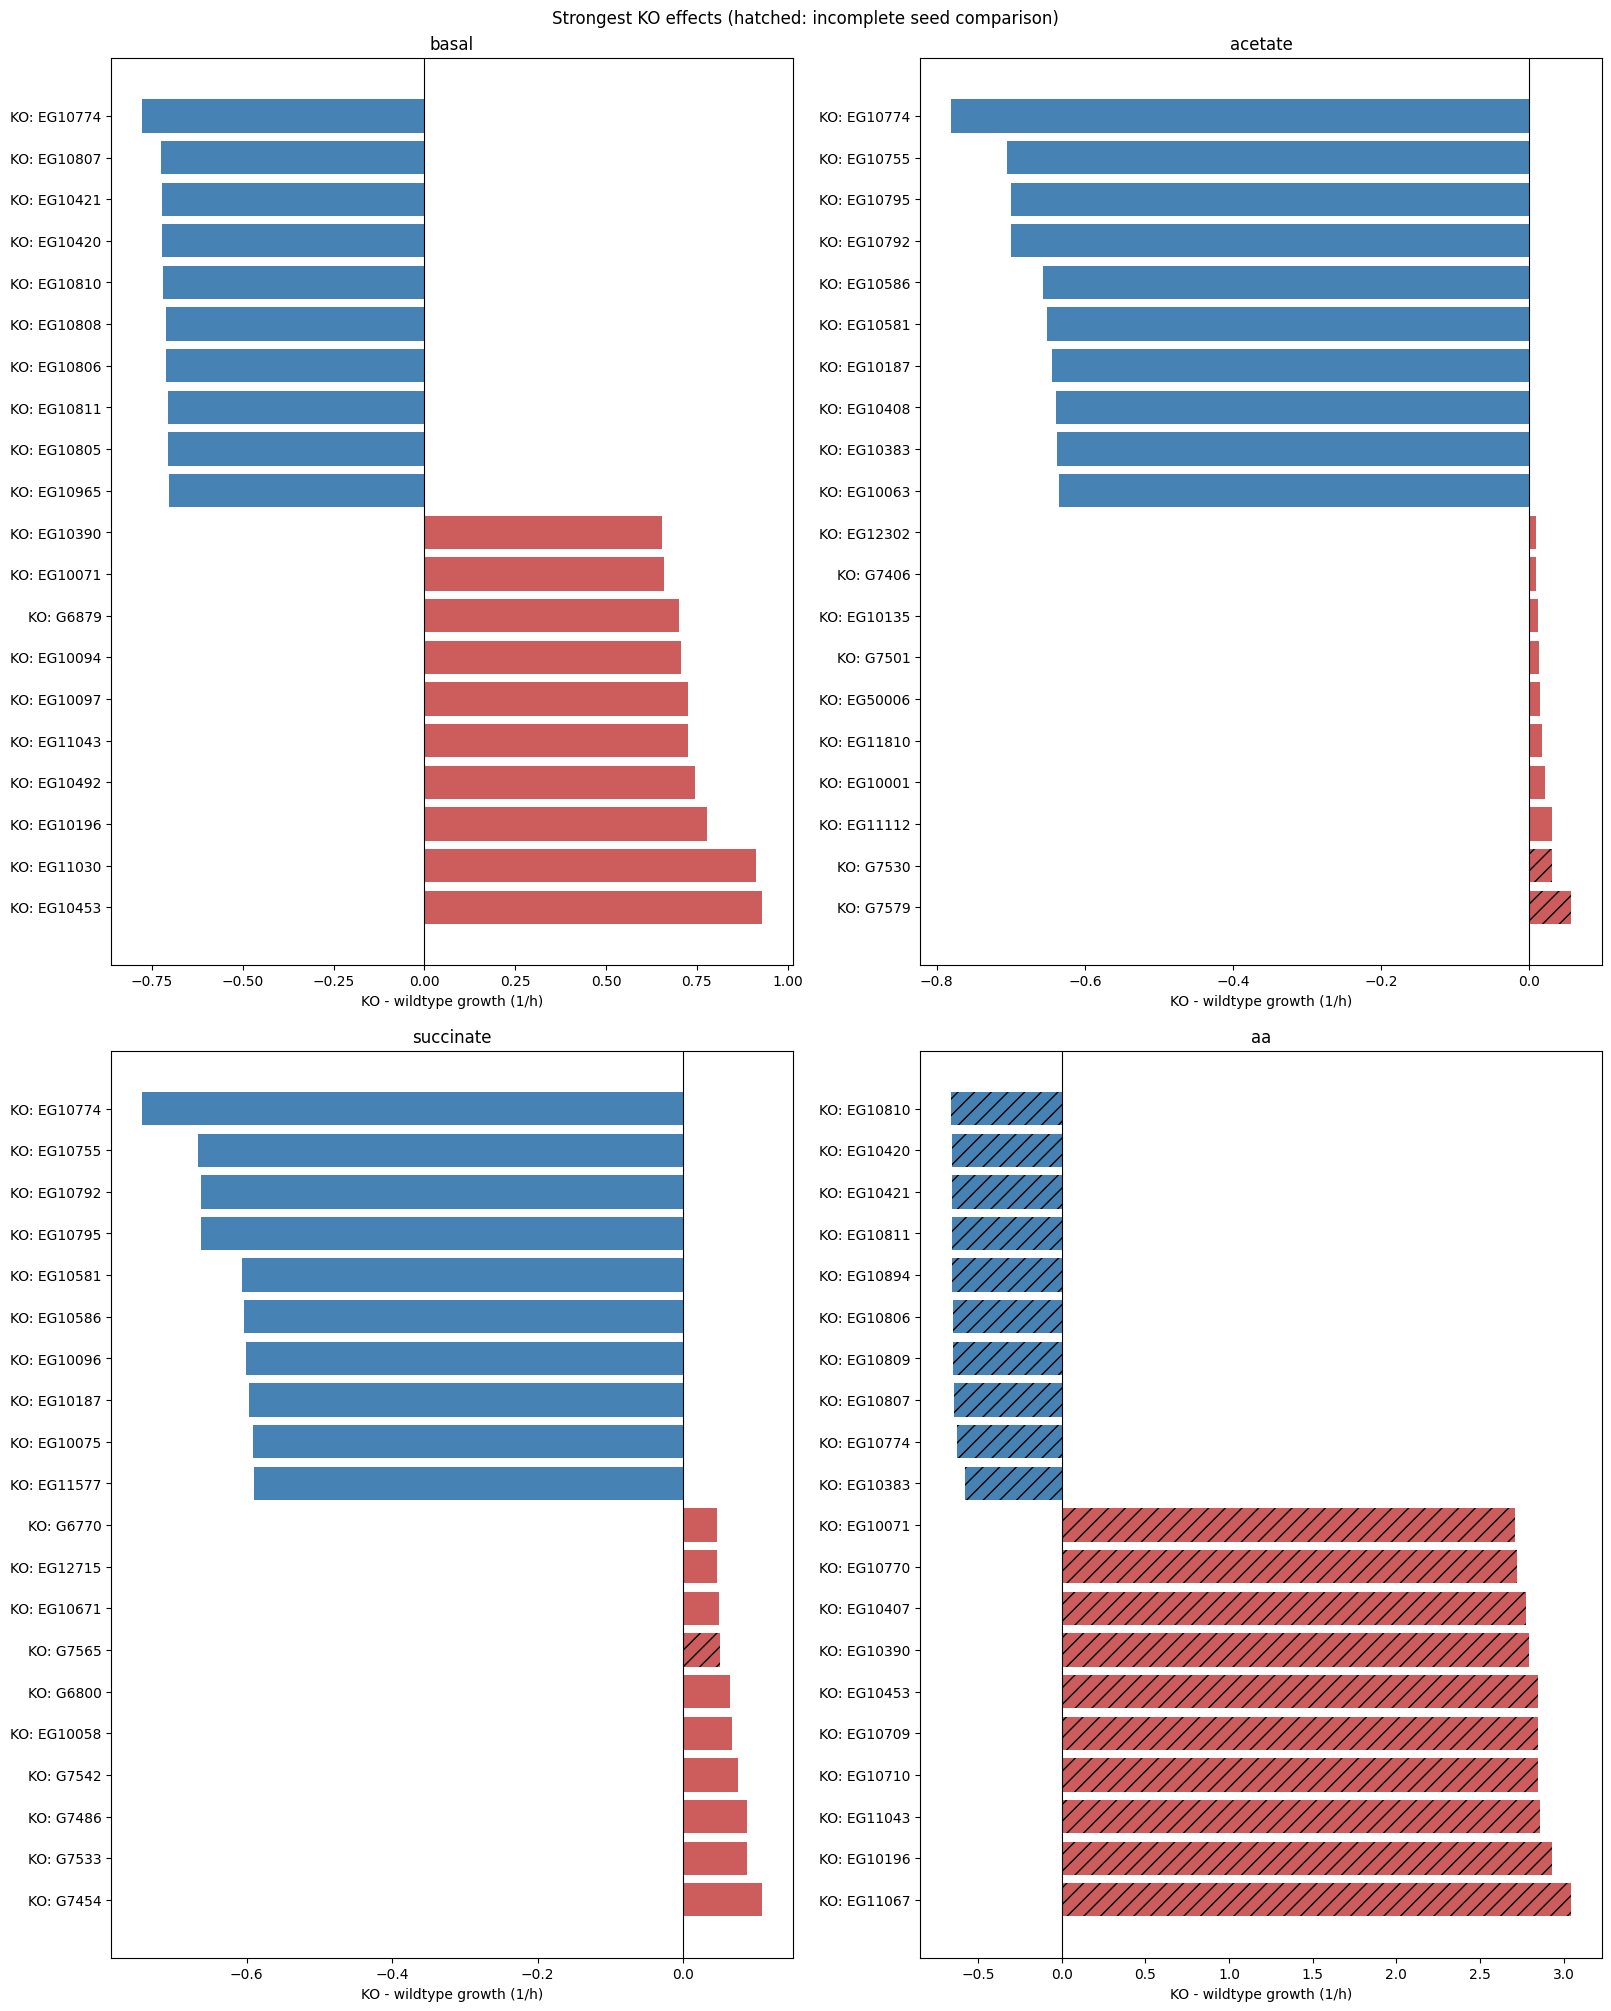

Strongest effects and interactions are shown in Steps 2 and 3. Hatched effects have fewer than two valid seeds; AA KO seed 101 is excluded. Seed-extrema ranges are not confidence intervals, and differing run durations can affect comparisons.


In [9]:
# Phase 2, Step 4: growth, KO effects and media-KO interactions
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

phase2_out = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
phase2_out.mkdir(parents=True, exist_ok=True)
phase2_growth.to_csv(phase2_out / "phase2_step4_growth.csv", index=False)
media = ["basal", "acetate", "succinate", "aa"]
genes = sorted(phase2_growth.loc[phase2_growth[GENE] != WILDTYPE, GENE].unique())
gene_positions = {gene: i for i, gene in enumerate([WILDTYPE] + genes)}
medium_positions = {medium: i for i, medium in enumerate(media)}

# All observed conditions; y-axis positions are categorical, not a continuous gene scale.
growth_plot = phase2_growth.dropna(subset=["mean_growth_rate"])
fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection="3d")
for medium, color in zip(media, sns.color_palette("tab10", 4)):
    points = growth_plot[(growth_plot["medium"] == medium) & (growth_plot[GENE] != WILDTYPE)]
    ax.scatter(points["medium"].map(medium_positions), points[GENE].map(gene_positions),
               points["mean_growth_rate"], color=color, s=6, alpha=0.65, label=medium)
    wt_points = growth_plot[(growth_plot["medium"] == medium) & (growth_plot[GENE] == WILDTYPE)]
    ax.scatter(wt_points["medium"].map(medium_positions), wt_points[GENE].map(gene_positions),
               wt_points["mean_growth_rate"], color=color, marker="*", s=100, edgecolors="black")
ax.set_xticks(range(len(media)), media)
ax.set_yticks([])
ax.set(xlabel="Medium", ylabel="Gene KO (categorical)", zlabel="Mean growth rate (1/h)",
       title="Growth by medium and genetic perturbation (stars: wildtype)")
ax.view_init(elev=25, azim=-55)
ax.zaxis.labelpad = 12
ax.legend(loc="upper left", bbox_to_anchor=(0, 1))
fig.subplots_adjust(left=0.02, right=0.92, bottom=0.04, top=0.94)
fig.savefig(phase2_out / "phase2_step4_growth_3d.png", dpi=200, bbox_inches="tight")
plt.show()

# Missing comparisons remain blank; basal is the reference, not an interaction column.
interaction_matrix = phase2_interactions.pivot(index=GENE, columns="medium", values="interaction")
interaction_matrix = interaction_matrix.reindex(index=genes, columns=media[1:])
fig, ax = plt.subplots(figsize=(8, 18))
ax.set_facecolor("lightgrey")
sns.heatmap(interaction_matrix, cmap="vlag", center=0, mask=interaction_matrix.isna(),
            yticklabels=25, cbar_kws={"label": "Interaction vs basal (1/h)"}, ax=ax)
ax.set(title=f"Media-KO interactions: {len(genes)} KOs (grey: missing)", xlabel="Medium", ylabel="Gene KO (every 25th labelled)")
fig.tight_layout()
fig.savefig(phase2_out / "phase2_step4_interaction_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

# Show the ten strongest decreases and increases in each medium.
fig, axes = plt.subplots(2, 2, figsize=(16, 20), constrained_layout=True)
for medium, ax in zip(media, axes.flat):
    effects = phase2_effects.loc[
        (phase2_effects["medium"] == medium) & phase2_effects["effect_vs_wildtype"].notna()
    ].sort_values("effect_vs_wildtype")
    extremes = pd.concat([effects[effects["effect_vs_wildtype"] < 0].head(10),
                          effects[effects["effect_vs_wildtype"] > 0].tail(10)])
    bars = ax.barh(extremes[GENE], extremes["effect_vs_wildtype"],
                   color=np.where(extremes["effect_vs_wildtype"] < 0, "steelblue", "indianred"))
    for bar, incomplete in zip(bars, extremes["comparison_incomplete"]):
        if incomplete:
            bar.set_hatch("//")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.invert_yaxis()
    ax.set(title=medium, xlabel="KO - wildtype growth (1/h)")
fig.suptitle("Strongest KO effects (hatched: incomplete seed comparison)")
fig.savefig(phase2_out / "phase2_step4_ko_effects.png", dpi=200, bbox_inches="tight")
plt.show()

print("Strongest effects and interactions are shown in Steps 2 and 3. Hatched effects have fewer than two valid seeds; AA KO seed 101 is excluded. Seed-extrema ranges are not confidence intervals, and differing run durations can affect comparisons.")

,observed,total,missing
medium,,,
aa,313,462,149
acetate,323,462,139
succinate,311,462,151


,medium,label,log_interaction,log_interaction_min,log_interaction_max,interaction_incomplete
299,aa,KO: EG10205,2.381378,2.294950,2.471591,True
359,aa,KO: EG10408,2.341867,2.278924,2.406334,True
416,aa,KO: EG10497,2.235983,2.115035,2.366456,True
413,aa,KO: EG10496,2.235983,2.115035,2.366456,True
446,aa,KO: EG10581,2.205887,2.154201,2.258453,True
495,acetate,KO: EG10755,-2.124463,-2.223444,-2.024021,False
496,succinate,KO: EG10755,-1.963970,-2.024736,-1.902542,False
396,acetate,KO: EG10453,-1.943906,-2.021924,-1.864645,False
1131,acetate,KO: EG11030,-1.914660,-2.022173,-1.804860,False
660,acetate,KO: EG10947,-1.892124,-1.981625,-1.800135,False


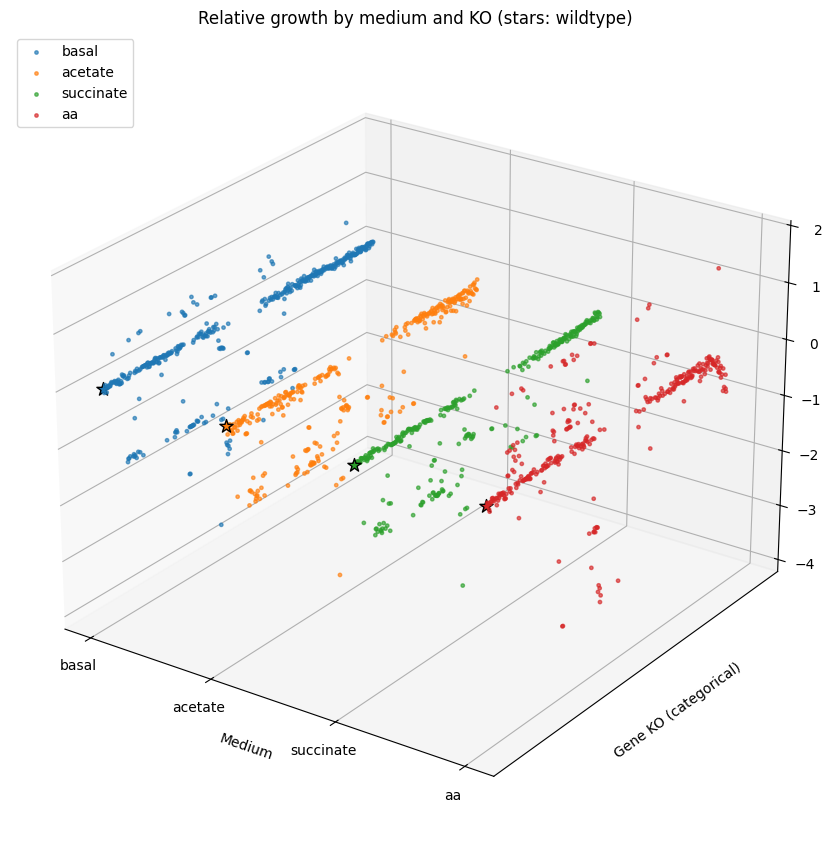

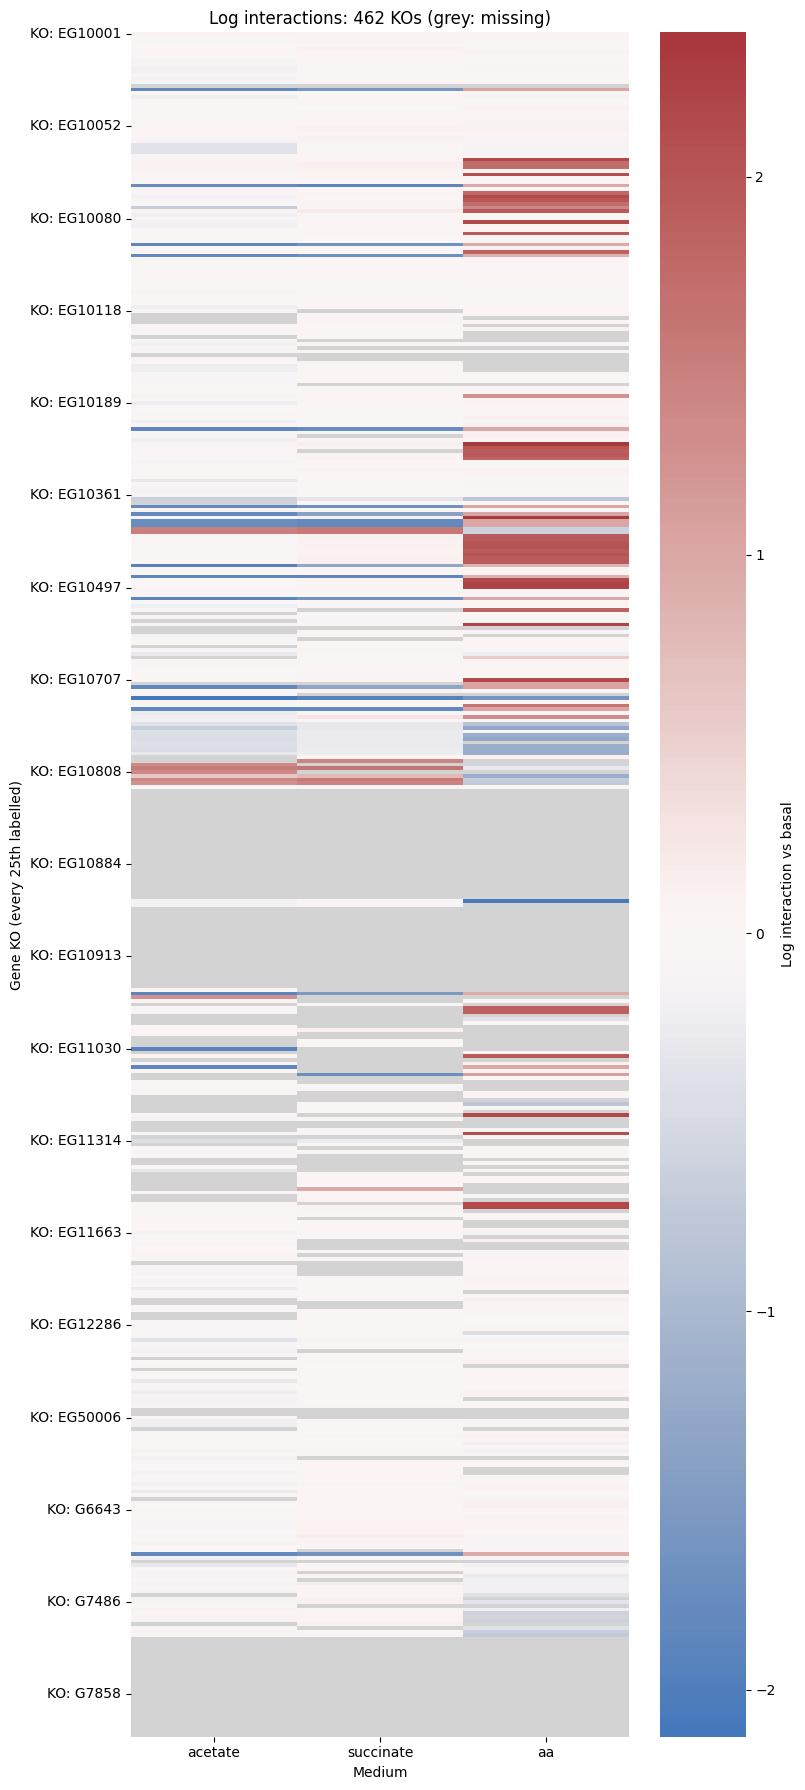

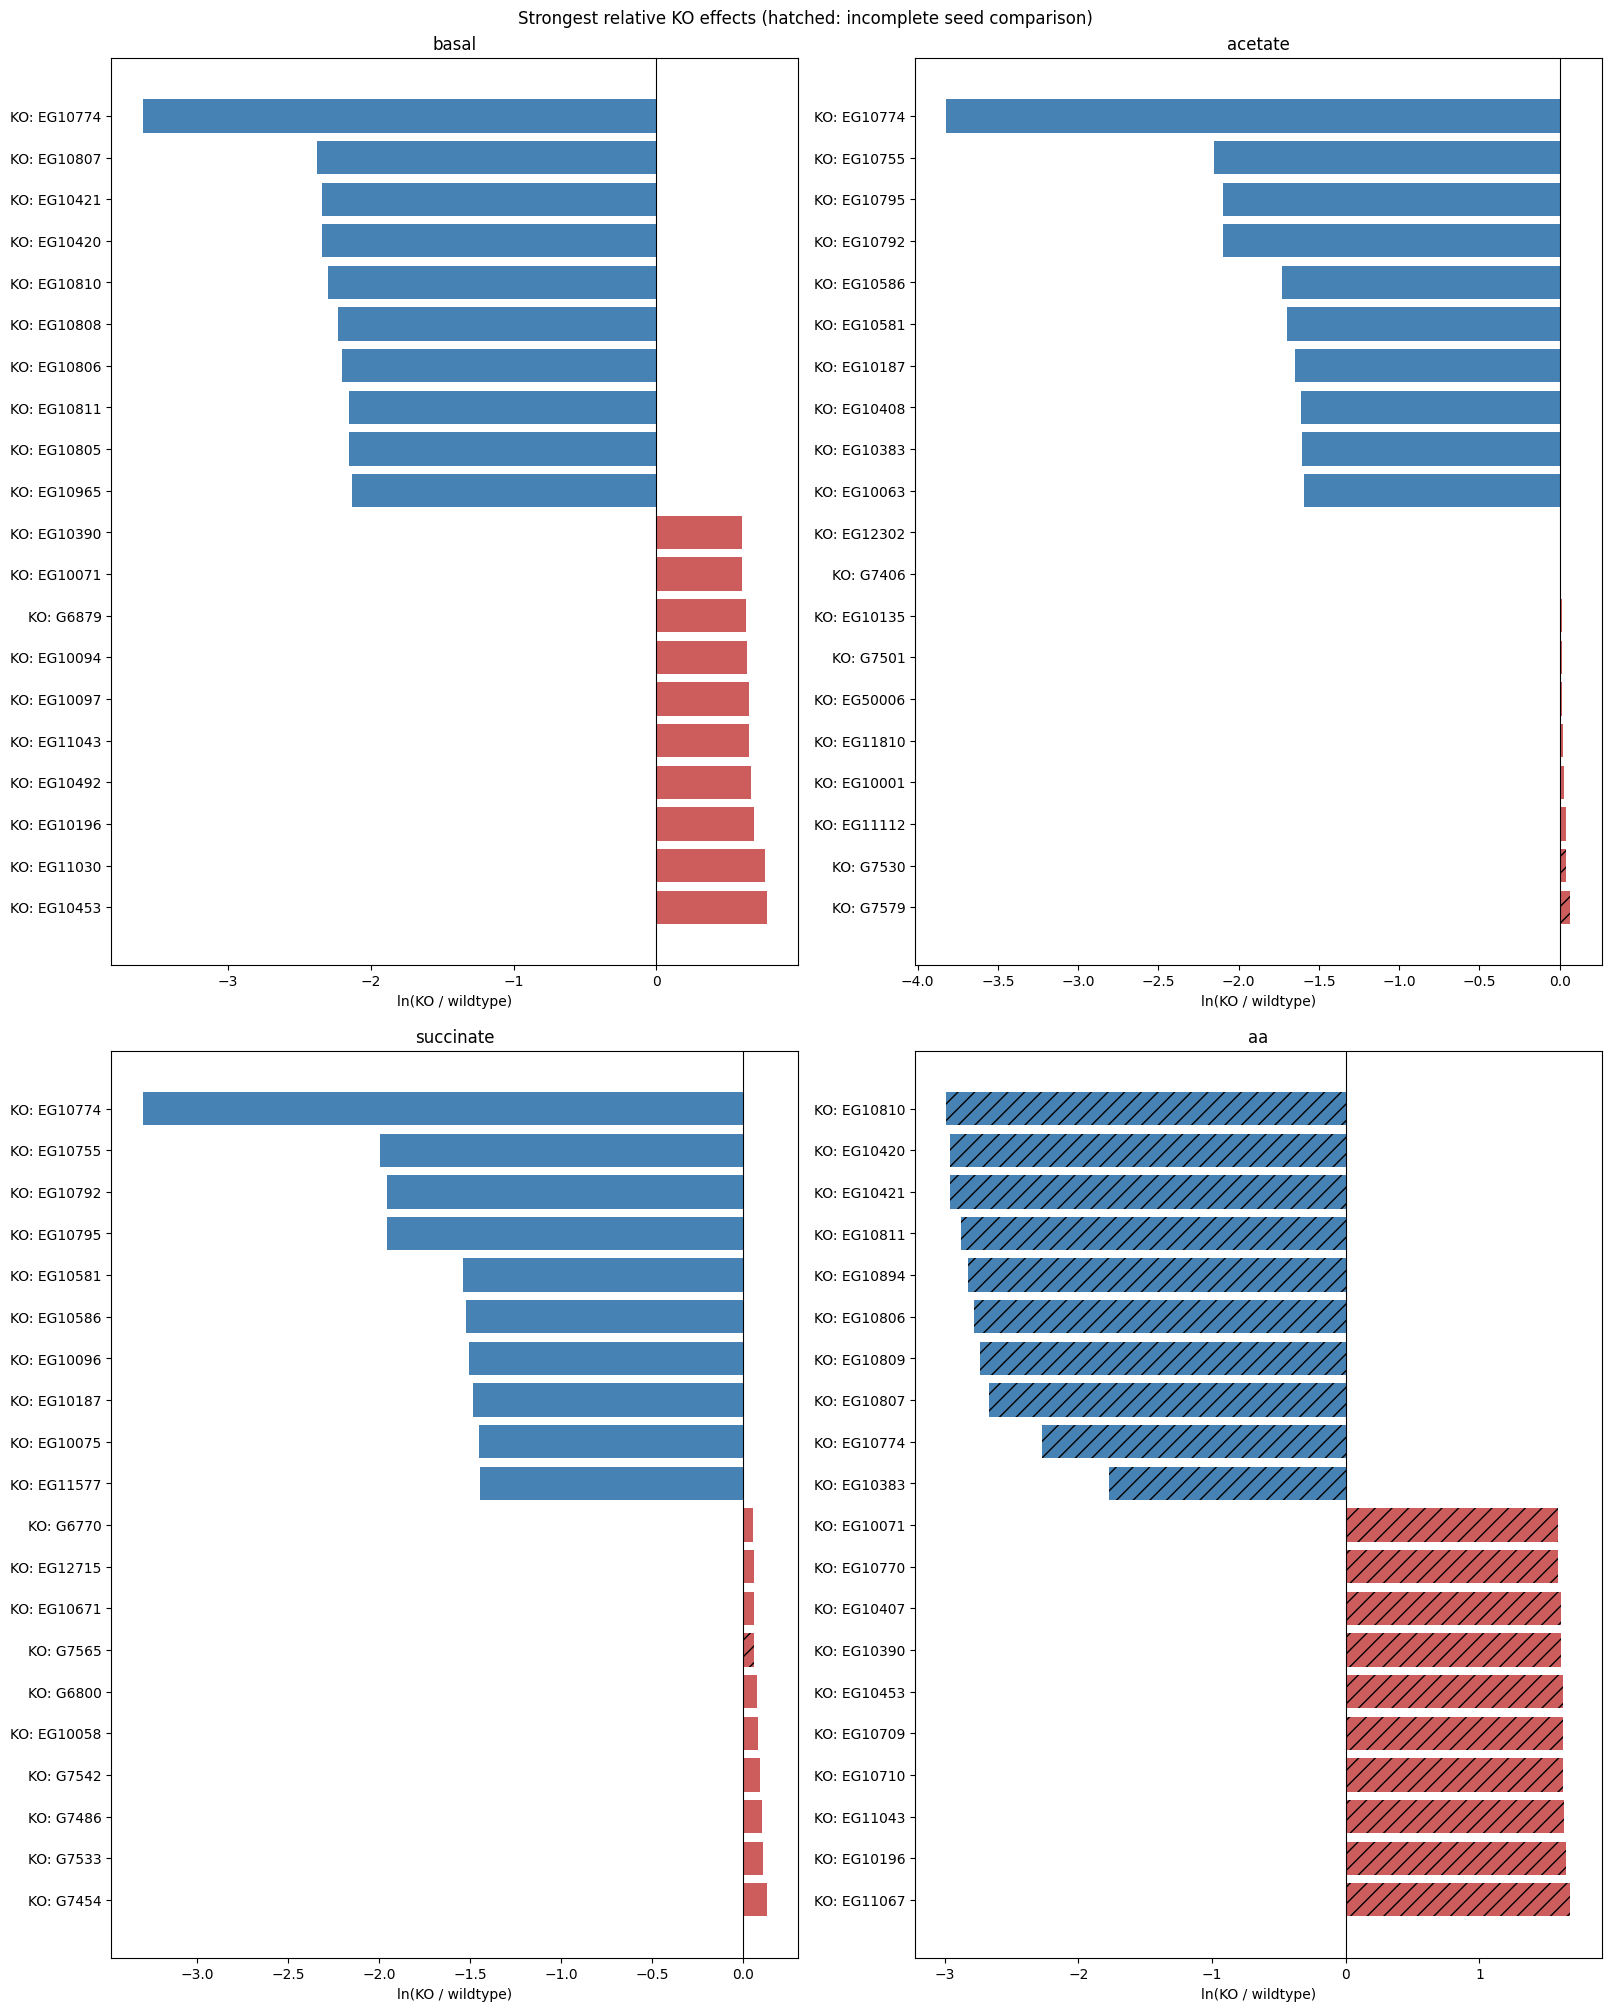

Log ratios describe relative effects, not proof of synergy. Single-seed conditions do not measure seed variability; run durations may differ.


In [10]:
# Phase 2, Step 3b: natural-log KO/wildtype ratios and interactions
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

log_out = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
log_out.mkdir(parents=True, exist_ok=True)
log_media = ["basal", "acetate", "succinate", "aa"]
log_effects = phase2_effects.copy()
ko_mean = log_effects["mean_growth_rate"]
wt_mean = log_effects["wildtype_mean_growth_rate"]
bad_means = (ko_mean.notna() & (ko_mean <= 0)) | (wt_mean.notna() & (wt_mean <= 0))
if bad_means.any():
    print(f"Nonpositive growth means: {bad_means.sum()} comparisons cannot use log ratios.")
log_effects["log_ko_wt"] = np.log(ko_mean.where(ko_mean > 0)) - np.log(wt_mean.where(wt_mean > 0))

basal_log = log_effects.loc[log_effects["medium"] == "basal", [
    GENE, "log_ko_wt", "n_valid_seeds", "wildtype_n_valid_seeds", "comparison_incomplete"
]].rename(columns={
    "log_ko_wt": "basal_log_ko_wt", "n_valid_seeds": "basal_n_valid_seeds",
    "wildtype_n_valid_seeds": "basal_wildtype_n_valid_seeds",
    "comparison_incomplete": "basal_comparison_incomplete",
})
log_interactions = log_effects.loc[log_effects["medium"] != "basal"].merge(
    basal_log, on=GENE, how="left", validate="many_to_one"
)
log_interactions["log_interaction"] = log_interactions["log_ko_wt"] - log_interactions["basal_log_ko_wt"]
log_interactions["interaction_incomplete"] = (
    log_interactions["comparison_incomplete"] | log_interactions["basal_comparison_incomplete"].fillna(True)
)

# Extrema vary seeds independently; these bounds are not confidence intervals.
log_seed_range = phase2_runs.groupby(["medium", GENE])["mean_growth_rate_per_hour"].agg(
    seed_min="min", seed_max="max"
).reset_index()
bad_seeds = log_seed_range["seed_min"].notna() & (log_seed_range["seed_min"] <= 0)
if bad_seeds.any():
    print(f"Nonpositive seed means: {bad_seeds.sum()} conditions have undefined log sensitivity bounds.")
log_seed_range["log_min"] = np.log(log_seed_range["seed_min"].where(log_seed_range["seed_min"] > 0))
log_seed_range["log_max"] = np.log(log_seed_range["seed_max"].where(log_seed_range["seed_min"] > 0))
log_wt_range = log_seed_range.loc[log_seed_range[GENE] == WILDTYPE, ["medium", "log_min", "log_max"]]
log_range = log_seed_range.loc[log_seed_range[GENE] != WILDTYPE].merge(
    log_wt_range, on="medium", how="left", suffixes=("_ko", "_wt"), validate="many_to_one"
)
log_range["log_effect_min"] = log_range["log_min_ko"] - log_range["log_max_wt"]
log_range["log_effect_max"] = log_range["log_max_ko"] - log_range["log_min_wt"]
log_range = log_range[["medium", GENE, "log_effect_min", "log_effect_max"]]
basal_log_range = log_range.loc[log_range["medium"] == "basal", [GENE, "log_effect_min", "log_effect_max"]].rename(
    columns={"log_effect_min": "basal_log_effect_min", "log_effect_max": "basal_log_effect_max"}
)
log_interactions = log_interactions.merge(log_range, on=["medium", GENE], how="left", validate="one_to_one")
log_interactions = log_interactions.merge(basal_log_range, on=GENE, how="left", validate="many_to_one")
log_interactions["log_interaction_min"] = log_interactions["log_effect_min"] - log_interactions["basal_log_effect_max"]
log_interactions["log_interaction_max"] = log_interactions["log_effect_max"] - log_interactions["basal_log_effect_min"]
log_effects.to_csv(log_out / "phase2_step3b_log_KO_effect.csv", index=False)
log_interactions.to_csv(log_out / "phase2_step3b_log_interactions.csv", index=False)
log_availability = log_interactions.groupby("medium")["log_interaction"].agg(observed="count", total="size")
log_availability["missing"] = log_availability["total"] - log_availability["observed"]
display(log_availability)
log_strongest = log_interactions.dropna(subset=["log_interaction"]).assign(
    magnitude=lambda x: x["log_interaction"].abs()
).sort_values("magnitude", ascending=False).groupby("medium", sort=False).head(5)
display(log_strongest[["medium", GENE, "log_interaction", "log_interaction_min", "log_interaction_max", "interaction_incomplete"]])

# Use the same categorical layout as Step 4, with log KO/wildtype on the z-axis.
log_genes = sorted(log_effects[GENE].unique())
log_positions = {gene: i for i, gene in enumerate([WILDTYPE] + log_genes)}
fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection="3d")
for i, (medium, color) in enumerate(zip(log_media, sns.color_palette("tab10", 4))):
    points = log_effects[(log_effects["medium"] == medium) & log_effects["log_ko_wt"].notna()]
    ax.scatter(np.full(len(points), i), points[GENE].map(log_positions), points["log_ko_wt"],
               color=color, s=6, alpha=0.65, label=medium)
    wt = phase2_growth[(phase2_growth["medium"] == medium) & (phase2_growth[GENE] == WILDTYPE)]
    if wt["mean_growth_rate"].gt(0).any():
        ax.scatter([i], [0], [0], color=color, marker="*", s=100, edgecolors="black")
ax.set_xticks(range(len(log_media)), log_media)
ax.set_yticks([])
ax.set(xlabel="Medium", ylabel="Gene KO (categorical)", zlabel="ln(KO / wildtype)",
       title="Relative growth by medium and KO (stars: wildtype)")
ax.view_init(elev=25, azim=-55)
ax.zaxis.labelpad = 12
ax.legend(loc="upper left", bbox_to_anchor=(0, 1))
fig.subplots_adjust(left=0.02, right=0.92, bottom=0.04, top=0.94)
fig.savefig(log_out / "phase2_step3b_log_growth_3d.png", dpi=200, bbox_inches="tight")
plt.show()

log_matrix = log_interactions.pivot(index=GENE, columns="medium", values="log_interaction")
log_matrix = log_matrix.reindex(index=log_genes, columns=log_media[1:])
fig, ax = plt.subplots(figsize=(8, 18))
ax.set_facecolor("lightgrey")
sns.heatmap(log_matrix, cmap="vlag", center=0, mask=log_matrix.isna(), yticklabels=25,
            cbar_kws={"label": "Log interaction vs basal"}, ax=ax)
ax.set(title=f"Log interactions: {len(log_genes)} KOs (grey: missing)",
       xlabel="Medium", ylabel="Gene KO (every 25th labelled)")
fig.tight_layout()
fig.savefig(log_out / "phase2_step3b_log_interaction_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(16, 20), constrained_layout=True)
for medium, ax in zip(log_media, axes.flat):
    effects = log_effects.loc[(log_effects["medium"] == medium) & log_effects["log_ko_wt"].notna()].sort_values("log_ko_wt")
    extremes = pd.concat([effects[effects["log_ko_wt"] < 0].head(10),
                          effects[effects["log_ko_wt"] > 0].tail(10)])
    bars = ax.barh(extremes[GENE], extremes["log_ko_wt"],
                   color=np.where(extremes["log_ko_wt"] < 0, "steelblue", "indianred"))
    for bar, incomplete in zip(bars, extremes["comparison_incomplete"]):
        if incomplete:
            bar.set_hatch("//")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.invert_yaxis()
    ax.set(title=medium, xlabel="ln(KO / wildtype)")
fig.suptitle("Strongest relative KO effects (hatched: incomplete seed comparison)")
fig.savefig(log_out / "phase2_step3b_log_KO_effects.png", dpi=200, bbox_inches="tight")
plt.show()
print("Log ratios describe relative effects, not proof of synergy. Single-seed conditions do not measure seed variability; run durations may differ.")

# Phase-3 Plan

- Aim: connect Phase 1/2 patterns to testable biological hypotheses and identify a knowledge-guided ML model that complements whole-cell modeling.

- Media details: [condition definitions](../reconstruction/ecoli/flat/condition/condition_defs.tsv) and [media recipes](../reconstruction/ecoli/flat/condition/media_recipes.tsv).

- Pathway references: [EcoCyc](https://ecocyc.org/) and [KEGG](https://www.kegg.jp/).

- Further study based on Phase 1 and Phase 2 results:

**Practical next step:** use EcoCyc/KEGG to map the strongest KO candidates to pathways, then test a small panel (`dapA`, `glyA`, `ilvE`, `ppa`, and selected synthetases) across all four media with matched run durations and additional seeds. Resolve the AA seed issue first: its Phase 2 KO comparisons currently rely on one seed, and Phase 1 has no AA KO seed pairs in the selected window. Test whether amino-acid supplementation selectively rescues biosynthesis-KO growth effects.\
Note in phase-2 discussion the gene ids are already converted to common gene names so ready for a search.

- Possible Future directions:

**ML follow-up:** predict the KO-by-medium interaction from pathway membership, media nutrients, and condition-specific TFs; evaluate on held-out genes/pathways and compare predicted effects with new whole-cell simulations. Treat incomplete runs and seed variation explicitly.


RxazN!7_mE

In [6]:
# Test BioCyc authorization with a single documented EcoCyc gene request.
from getpass import getpass
from time import sleep
from xml.etree import ElementTree as ET
import requests

email = input("BioCyc account email: ")
password = getpass("BioCyc password: ")
biocyc_session = requests.Session()
try:
    login = biocyc_session.post(
        "https://websvc.biocyc.org/credentials/login/",
        data={"email": email, "password": password}, timeout=30,
    )
    login.raise_for_status()
finally:
    del email, password

if not biocyc_session.cookies:
    raise RuntimeError("BioCyc did not return a session cookie; check the login.")

sleep(1)
response = biocyc_session.get(
    "https://websvc.biocyc.org/getxml",
    params={"id": "ECOLI:EG11025", "detail": "low"}, timeout=30,
)
response.raise_for_status()
try:
    root = ET.fromstring(response.content)
except ET.ParseError as exc:
    raise ValueError("BioCyc returned non-XML; check account access.") from exc
gene = root.find("Gene")
if root.tag != "ptools-xml" or root.find("Error") is not None or gene is None or gene.get("frameid") != "EG11025":
    raise ValueError("BioCyc did not return the requested gene; check account access.")
print("BioCyc authorization successful: retrieved EcoCyc gene EG11025.")

BioCyc authorization successful: retrieved EcoCyc gene EG11025.


In [9]:
# Search BioCyc for the candidates selected in the Phase 2 discussion, not every gene.
# Phase 2 tables supply their gene IDs and medium-specific scores and completeness flags,
# so the retrieved annotations can be compared with the simulation results.

from pathlib import Path
from getpass import getpass
from time import monotonic, sleep
from xml.etree import ElementTree as ET

import pandas as pd
import requests
from IPython.display import display

results_dir = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
candidates = pd.read_csv(results_dir / "phase2_top_influencer.csv")["gene_name"].dropna().unique().tolist()
files = {
    "additive_effect": ("phase2_step2_KO_effect.csv", "effect_vs_wildtype", "comparison_incomplete"),
    "additive_interaction": ("phase2_step3_interactions.csv", "interaction", "interaction_incomplete"),
    "log_effect": ("phase2_step3b_log_KO_effect.csv", "log_ko_wt", "comparison_incomplete"),
    "log_interaction": ("phase2_step3b_log_interactions.csv", "log_interaction", "interaction_incomplete"),
}

tables = {}
for name, (file_name, score, incomplete) in files.items():
    table = pd.read_csv(results_dir / file_name)
    tables[name] = table.loc[table["gene_name"].isin(candidates), [
        "medium", "gene_id", "gene_name", score, incomplete
    ]].rename(columns={score: name, incomplete: f"{name}_incomplete"})

gene_ids = tables["additive_effect"][["gene_id", "gene_name"]].drop_duplicates()
if set(gene_ids["gene_name"]) != set(candidates) or gene_ids["gene_name"].duplicated().any():
    raise ValueError("Candidate gene names must each match exactly one gene ID in the Phase 2 results.")

comparison = tables["additive_effect"]
for name in ("additive_interaction", "log_effect", "log_interaction"):
    comparison = comparison.merge(tables[name], on=["medium", "gene_id", "gene_name"],
                                  how="left", validate="one_to_one")

# BioCyc requires an authenticated session; credentials are not saved to the notebook.
email = input("BioCyc account email: ")
password = getpass("BioCyc password: ")
session = requests.Session()
last_request = 0.0

def biocyc_request(method, path, **kwargs):
    global last_request
    sleep(max(0.0, 1.0 - (monotonic() - last_request)))
    last_request = monotonic()
    response = session.request(method, f"https://websvc.biocyc.org/{path}", timeout=30, **kwargs)
    response.raise_for_status()
    return response

login = biocyc_request("POST", "credentials/login/", data={"email": email, "password": password})
del email, password
if not session.cookies:
    raise RuntimeError("BioCyc login did not return a session cookie; check account access.")

def biocyc_objects(gene_id, function, object_type):
    response = biocyc_request("GET", "apixml", params={
        "fn": function, "id": f"ECOLI:{gene_id}", "detail": "low"
    })
    try:
        root = ET.fromstring(response.content)
    except ET.ParseError as exc:
        raise ValueError(f"BioCyc returned non-XML for {gene_id} ({function}); check login and access.") from exc
    if root.tag != "ptools-xml" or root.find("metadata") is None:
        raise ValueError(f"Unexpected BioCyc response for {gene_id} ({function}).")
    if root.find("Error") is not None:
        raise ValueError(f"BioCyc returned an error for {gene_id} ({function}).")
    objects = root.findall(object_type)
    if any(not obj.get("frameid") for obj in objects):
        raise ValueError(f"BioCyc returned an object without an ID for {gene_id} ({function}).")
    return [(obj.get("frameid"), "".join(obj.find("common-name").itertext()).strip()
             if obj.find("common-name") is not None else "") for obj in objects]

annotations = []
for gene in gene_ids.itertuples(index=False):
    products = biocyc_objects(gene.gene_id, "all-products-of-gene", "Protein")
    pathways = biocyc_objects(gene.gene_id, "pathways-of-gene", "Pathway")
    annotations.append({
        "gene_id": gene.gene_id,
        "gene_name": gene.gene_name,
        "product_ids": "; ".join(item[0] for item in products),
        "product_names": "; ".join(item[1] for item in products),
        "pathway_ids": "; ".join(item[0] for item in pathways),
        "pathway_names": "; ".join(item[1] for item in pathways),
        "biocyc_url": f"https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&object={gene.gene_id}",
    })

phase3_annotations = pd.DataFrame(annotations)
phase3_comparison = comparison.merge(phase3_annotations, on=["gene_id", "gene_name"],
                                     how="left", validate="many_to_one")
phase3_annotations.to_csv(results_dir / "phase3_biocyc_annotations.csv", index=False)
phase3_comparison.to_csv(results_dir / "phase3_candidate_comparisons.csv", index=False)
display(phase3_annotations)
print("Empty product/pathway fields mean BioCyc returned no matching objects. AA incomplete comparisons require additional seeds; interactions do not prove causation.")

,gene_id,gene_name,product_ids,product_names,pathway_ids,pathway_names,biocyc_url
0,EG10196,cysS,CYSS-MONOMER,cysteine&mdash;tRNA ligase,TRNA-CHARGING-PWY,tRNA charging,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
1,EG10205,dapA,DIHYDRODIPICSYN-MONOMER; DIHYDRODIPICSYN-CPLX,4-hydroxy-tetrahydrodipicolinate synthase; 4-h...,DAPLYSINESYN-PWY,L-lysine biosynthesis I,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
2,EG10408,glyA,GLYOHMETRANS-MONOMER; GLYOHMETRANS-CPLX,serine hydroxymethyltransferase; serine hydrox...,PWY0-1535; GLYSYN-PWY; PWY-2161; 1CMET2-PWY; P...,D-serine degradation; glycine biosynthesis I; ...,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
3,EG10453,hisS,HISS-MONOMER; HISS-CPLX,histidine&mdash;tRNA ligase;,TRNA-CHARGING-PWY,tRNA charging,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
4,EG10492,ileS,ILES-MONOMER,isoleucine&mdash;tRNA ligase,TRNA-CHARGING-PWY,tRNA charging,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
5,EG10497,ilvE,BRANCHED-CHAINAMINOTRANSFER-MONOMER; BRANCHED-...,branched-chain-amino-acid aminotransferase; br...,PHESYN; VALSYN-PWY; ILEUSYN-PWY; LEUSYN-PWY,L-phenylalanine biosynthesis I; L-valine biosy...,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
6,EG10755,ppa,INORGPYROPHOSPHAT-MONOMER; CPLX0-243,inorganic pyrophosphatase; inorganic pyrophosp...,PWY-7805,(aminomethyl)phosphonate degradation,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
7,EG11030,trpS,TRPS-MONOMER; TRPS-CPLX,tryptophan&mdash;tRNA ligase; tryptophan&mdash...,TRNA-CHARGING-PWY,tRNA charging,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...


Empty product/pathway fields mean BioCyc returned no matching objects. AA incomplete comparisons require additional seeds; interactions do not prove causation.


### BioCyc search results

The [BioCyc annotations](results/pattern/phase3_biocyc_annotations.csv) link `dapA` to lysine biosynthesis, `glyA` to glycine and folate pathways, and `ilvE` to branched-chain amino-acid biosynthesis. Their positive AA log interactions (+2.381, +2.342 and +2.236) suggest that supplementation might alter their KO effects, but do not establish rescue.

`hisS`, `trpS`, `cysS` and `ileS` are annotated with tRNA charging; their negative acetate or succinate interactions suggest a shared category to investigate. `ppa` encodes inorganic pyrophosphatase and also shows negative log interactions in acetate (-2.124) and succinate (-1.964). These annotations identify possible explanations, not proven mechanisms.

The [combined comparison table](results/pattern/phase3_candidate_comparisons.csv) retains the Phase 2 scores and completeness flags. AA comparisons rely on one KO seed, and some values are missing; confirm the patterns with additional seeds and matched run durations before drawing biological conclusions.

# Results & Discussion

## Phase 1 Discussion

### Step 0 - Simulation validity and generations reached

The [Step 0 inventory table](results/pattern/step0_metadata_inventory.csv) compares folders and current metadata with KO and baseline run counts read from the saved summary files. After updating the summaries or metadata, rerun Step 0 and the table display below to refresh the results. Metadata-backed totals assume both original KO seeds (100 and 101) and two baseline seeds; AA baseline uses seeds 1 and 2. The additional AA seed-1 KO jobs are not included. Metadata alone does not establish that a run was submitted or produced output.

In [11]:
import pandas as pd
from IPython.display import display

display(pd.read_csv("/user/home/il22158/work/vEcoli/reading/results/pattern/step0_metadata_inventory.csv", index_col="medium"))

,original project folders,KO variants with metadata,metadata-backed KO runs,KO runs in summary,baseline runs in summary,metadata-backed total including baseline
medium,,,,,,
basal,5,462,924,924,2,926
acetate,435,360,720,715,2,722
succinate,435,343,686,682,2,688
aa,435,349,698,697,2,700


The [run-status table](results/pattern/step0_run_status_per_KO_seed_media.csv) records validity and generation outcome for runs present in the time-series data. A valid run has more than one distinct positive time point with finite growth rate; a valid run below the target is not equivalent to an invalid run. Missing summary or time-series records do not necessarily indicate failed simulations. Differences in availability and completion can affect the subset used for comparisons; consult the extraction and original simulation logs to investigate missing output.

[Maximum generation reached by valid KO-seed runs in each medium](results/pattern/step0_max_generation_stacked_bar.png)

### Step alpha - Temporal pattern and window selection

The generation-level means support treating early generations separately from the later, more stable period. AA rises sharply through generations 3-4 (about 1.04 and 1.25 1/h) before settling near 0.74-0.78 from generation 5 onward. Succinate increases from about 0.67 at generation 1 to roughly 0.76 by generation 4, while acetate rises from about 0.60 at generation 1 to around 0.75 by generation 2. Basal is comparatively steady overall but has an early peak near 0.90 at generation 3 before returning to about 0.77. The raw per-run points also show substantial early-generation heterogeneity, so these mean trajectories should not be read as every KO following the same course. The selected windows (basal and succinate: generations 4-11; acetate: 3-10; AA: 6-13) exclude the strongest medium-specific transients and make the per-KO comparison more representative of the later pattern. This choice is a practical summary window, not evidence that early-generation behavior is biologically unimportant.

[Per-run and mean growth-rate trajectories across generations](results/pattern/step3_temporal_pattern.png)

### Step 1 - Per-KO growth rates and seed agreement

Step 1a summarizes each valid run using all available time points; its per-KO distribution is based on KOs with a value in all four media. Step 1 instead applies the generation windows and compares the common-KO set within those windows. The Step 1a plot therefore provides an all-time-point reference, while Step 1 focuses on the selected temporal region.

[Step 1a: per-KO growth-rate distributions from all valid-run time points](results/pattern/step1a_per_KO_distribution.png)
The all-time-point seed scatter is close to the 1:1 line for many basal, acetate, and succinate KOs, although outliers show that agreement is not universal. AA is notably discordant: many pairs fall well below the 1:1 line, and its selected-window paired-seed plot contains no KO pairs (n=0). The AA result therefore cannot be used to assess seed reproducibility within the selected window; the known AA seed/simulation issue should be resolved before making a paired-seed comparison. The plotted n values are medium-specific counts with both seed means, not the 171-condition common-set count.

[All-time-point seed-to-seed growth-rate agreement](results/pattern/step1a_seed_agreement.png)

Applying the windows selected in Step alpha leaves 177 KOs common to all four media, so the selected-window distribution represents a narrower set than the all-time-point analysis. The [selected-window seed-agreement plot](results/pattern/step1_seed_agreement.png) and [selected-window per-KO distribution](results/pattern/step1_per_KO_distribution.png) may therefore look less complete or smooth. In particular, the AA seed-101 simulation failure leaves no paired AA KO observations in this window (n=0); that panel cannot assess AA seed reproducibility and should not be interpreted as a biological pattern. These coverage and seed limitations, rather than a failure of the plotting method, explain why the selected-window figures may look less ideal.


### Step 2 - Growth-rate distributions

The all-time-point distributions have a dominant peak around 0.7-0.8 1/h in every medium, so their central growth rates are broadly similar. They are not well described as simply normal: each has a low-growth tail or secondary low-growth component, most visibly in AA, where a distinct lower mode appears. The all-time-point medians are 0.786 (basal), 0.759 (acetate), 0.766 (succinate), and 0.720 1/h (AA); the corresponding means are 0.732, 0.721, 0.727, and 0.662 1/h. The lower AA mean is consistent with its larger low-growth component, while the histogram and violin also show substantial overlap among media. Because this plot uses all time points rather than the common-KO, selected-window summaries above, the two sets of statistics answer different questions.

[All-time-point growth-rate histograms, KDEs, and violin plots by medium](results/pattern/step2_timepoints_all.png)

## Phase 2 Discussion

In [ ]:
# Convert gene IDs to common gene names

from pathlib import Path
import pandas as pd

results_dir = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
genes_path = Path("/user/home/il22158/work/vEcoli/reconstruction/ecoli/flat/genes.tsv")
gene_names = pd.read_csv(genes_path, sep="\t", comment="#", usecols=["id", "symbol"])
gene_names = gene_names.rename(columns={"id": "gene_id", "symbol": "gene_name"})
gene_map = gene_names.set_index("gene_id")["gene_name"]

result_files = [
    "phase2_step2_KO_effect.csv",
    "phase2_step3_interactions.csv",
    "phase2_step3b_log_KO_effect.csv",
    "phase2_step3b_log_interactions.csv",
]

for file_name in result_files:
    csv_path = results_dir / file_name
    data = pd.read_csv(csv_path).drop(columns=["gene_id", "gene_name"], errors="ignore")
    data["gene_id"] = data["label"].str.extract(r"KO:\s*(\S+)", expand=False)
    data["gene_name"] = data["gene_id"].map(gene_map)
    unmapped = data["gene_id"].notna() & data["gene_name"].isna()
    if unmapped.any():
        raise ValueError(f"No gene symbol found for: {data.loc[unmapped, 'gene_id'].unique().tolist()}")
    data.to_csv(csv_path, index=False)
    print(f"Updated {file_name}: {data['gene_name'].notna().sum()} gene names")

The top-10 increases and decreases are ranked in the preceding Phase 2 code cells for both comparison methods; this cell does not rank or alter those selections. It only adds gene names to the four saved result tables, preserving their rows and order. The simple-subtraction results are `phase2_step2_KO_effect.csv` and `phase2_step3_interactions.csv`; the log-ratio results are `phase2_step3b_log_KO_effect.csv` and `phase2_step3b_log_interactions.csv`.

For all four CSVs, the Python cell extracts the full identifier after `KO:` (including IDs such as `G0-10441`), maps it to the `id` column in [genes.tsv](../reconstruction/ecoli/flat/genes.tsv), adds `gene_id` and `gene_name`, and saves each annotated table back to the same path. The matching `symbol` is the common gene name, for example `EG10205` -> `dapA`. Biological pathway interpretation is reserved for Phase 3.

### Step 1 - Coverage and comparison setup

Phase 2 averages each valid run over its available finite, nonzero-time observations, then compares each KO with the wildtype from the same medium. The additive KO effects and interactions are in [Step 2](results/pattern/phase2_step2_KO_effect.csv) and [Step 3](results/pattern/phase2_step3_interactions.csv); their log-ratio counterparts are in [Step 3b KO effects](results/pattern/phase2_step3b_log_KO_effect.csv) and [Step 3b interactions](results/pattern/phase2_step3b_log_interactions.csv). Interactions are reported only for observed KO-medium combinations: 313/462 for AA, 323/462 for acetate, and 311/462 for succinate. Missing combinations are not zero-filled.

### Step 2 - KO effects relative to wildtype

The additive effect is `KO growth rate - wildtype growth rate`; the log effect is `ln(KO growth rate / wildtype growth rate)`. Both top-10 lists identify `prs` (EG10774) as a strong growth-decreasing KO: its additive effects are -0.780 1/h in acetate and -0.743 1/h in succinate, while its log effects are -3.822 and -3.300, respectively. Log scores express a ratio and are not directly comparable in magnitude with additive growth-rate differences. The [additive KO-effect plot](results/pattern/phase2_step4_ko_effects.png) and [log KO/WT plot](results/pattern/phase2_step3b_log_KO_effects.png) show the medium-specific distributions and ranked extremes.

The largest positive additive KO effects occur in AA (for example, `valS` at +3.043 1/h), but these AA KO comparisons use one valid seed and are flagged incomplete. They should not be read as validated growth benefits.

### Step 3 - Media-KO interaction relative to basal

An additive interaction is the KO-versus-wildtype effect in a test medium minus that KO effect in basal; the log interaction applies the same contrast to the log ratios. Negative values indicate a more unfavorable KO effect relative to basal, and positive values a more favorable one. The additive results highlight `hisS` (-1.479) and `trpS` (-1.458) in acetate, and `cysS` (-1.284) and `ileS` (-1.283) in succinate. The log results also flag `ppa` in acetate (-2.124) and succinate (-1.964), alongside several aminoacyl-tRNA synthetases. In AA, the strongest positive log interactions include `dapA` (+2.381), `glyA` (+2.342), and `ilvE` (+2.236); each is based on one KO seed and flagged incomplete. The [additive interaction heatmap](results/pattern/phase2_step4_interaction_heatmap.png) and [log interaction heatmap](results/pattern/phase2_step3b_log_interaction_heatmap.png) show the broader pattern.

### Takeaways
The two methods broadly point to medium-dependent KO effects but do not produce identical rankings: additive differences use growth-rate units, whereas log ratios emphasize proportional changes. Treat the repeated acetate/succinate signals as candidates for follow-up, not evidence of synergy or mechanism. Seed counts are small, AA has the known seed issue, and run durations vary; the seed-extrema ranges are not confidence intervals.

The table below compares the eight manually selected Phase 3 candidates across media using both methods. Run the cell to refresh the [candidate table](results/pattern/phase2_top_influencer.csv) before the Phase 3 BioCyc search.

In [3]:
# The Phase 3 panel was selected from the Phase 2 discussion, not by a new ranking.
from pathlib import Path
import pandas as pd
from IPython.display import display

results_dir = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
candidates = ["dapA", "glyA", "ilvE", "ppa", "hisS", "trpS", "cysS", "ileS"]
sources = {
    "additive_effect": ("phase2_step2_KO_effect.csv", "effect_vs_wildtype", "comparison_incomplete"),
    "log_effect": ("phase2_step3b_log_KO_effect.csv", "log_ko_wt", "comparison_incomplete"),
    "additive_interaction": ("phase2_step3_interactions.csv", "interaction", "interaction_incomplete"),
    "log_interaction": ("phase2_step3b_log_interactions.csv", "log_interaction", "interaction_incomplete"),
}

tables = {}
for name, (file_name, score, incomplete) in sources.items():
    data = pd.read_csv(results_dir / file_name)
    columns = ["medium", "gene_id", "gene_name", score, incomplete]
    if name == "additive_effect":
        columns.extend(["n_valid_seeds", "wildtype_n_valid_seeds"])
    tables[name] = data.loc[data["gene_name"].isin(candidates), columns].rename(
        columns={score: name, incomplete: f"{name}_incomplete"}
    )

top_influencers = tables["additive_effect"]
if set(top_influencers["gene_name"]) != set(candidates):
    raise ValueError("Some selected candidates are absent from the Phase 2 results.")
for name in ("log_effect", "additive_interaction", "log_interaction"):
    top_influencers = top_influencers.merge(
        tables[name], on=["medium", "gene_id", "gene_name"], how="left", validate="one_to_one"
    )

top_influencers.to_csv(results_dir / "phase2_top_influencer.csv", index=False)
display(top_influencers.round(3))
print("Additive scores are in 1/h; log scores are dimensionless. Basal interactions are not applicable; other missing scores are unavailable. Incomplete flags mark limited seed comparisons.")

,medium,gene_id,gene_name,additive_effect,additive_effect_incomplete,n_valid_seeds,wildtype_n_valid_seeds,log_effect,log_effect_incomplete,additive_interaction,additive_interaction_incomplete,log_interaction,log_interaction_incomplete
0,basal,EG10196,cysS,0.779,False,2,2,0.681,False,NaN,NaN,NaN,NaN
1,acetate,EG10196,cysS,-0.555,False,2,2,-1.188,False,-1.333,False,-1.869,False
2,succinate,EG10196,cysS,-0.505,False,2,2,-1.062,False,-1.284,False,-1.743,False
3,aa,EG10196,cysS,2.929,True,1,2,1.650,True,2.150,True,0.969,True
4,basal,EG10205,dapA,-0.625,False,2,2,-1.530,False,NaN,NaN,NaN,NaN
5,acetate,EG10205,dapA,-0.626,False,2,2,-1.537,False,-0.001,False,-0.007,False
6,succinate,EG10205,dapA,-0.579,False,2,2,-1.385,False,0.047,False,0.144,False
7,aa,EG10205,dapA,0.935,True,1,2,0.852,True,1.560,True,2.381,True
8,basal,EG10408,glyA,-0.628,False,2,2,-1.544,False,NaN,NaN,NaN,NaN
9,acetate,EG10408,glyA,-0.639,False,2,2,-1.612,False,-0.011,False,-0.068,False


Additive scores are in 1/h; log scores are dimensionless. Basal interactions are not applicable; other missing scores are unavailable. Incomplete flags mark limited seed comparisons.
